# Accuracy Improvement

**Cell 1 — Clone repository and check GPU**

In [1]:

import os
import sys
import subprocess
from pathlib import Path

PROJECT_ROOT = Path("/kaggle/working/HAR-MMAct")

if not PROJECT_ROOT.exists():
    subprocess.run(
        [
            "git", "clone", "--depth", "1",
            "--branch", "master",
            "https://github.com/CHENNAMSETTYVIKRAM/HAR-MMAct.git",
            str(PROJECT_ROOT)
        ],
        check=True
    )

os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT))

import torch
import torchvision
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

assert torch.cuda.is_available(), "Enable GPU in Kaggle settings."

torch.set_num_threads(min(4, os.cpu_count() or 1))

DEVICE = torch.device("cuda")
GPU_NAME = torch.cuda.get_device_name(0)

print("Repository:", PROJECT_ROOT)
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("GPU:", GPU_NAME)
print("GPU memory:", round(
    torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
), "GB")

# Download/cache the official ImageNet MobileNetV2 weights now.
from torchvision.models import mobilenet_v2, MobileNet_V2_Weights

_ = mobilenet_v2(weights=MobileNet_V2_Weights.DEFAULT)

print("ImageNet MobileNetV2 weights verified and cached.")


Cloning into '/kaggle/working/HAR-MMAct'...
Updating files: 100% (990/990), done.


Repository: /kaggle/working/HAR-MMAct
PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
GPU: Tesla T4
GPU memory: 14.56 GB
Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 127MB/s]

ImageNet MobileNetV2 weights verified and cached.


**Dataset verification**

In [2]:

from pathlib import Path

from src.data.stager import (
    FastMMActStager,
    discover_kaggle_input_roots
)
from src.data.indexer import MMActIndexer
from src.data.splits import (
    DatasetSplitter,
    verify_split_isolation
)
from src.config import (
    SplitConfig,
    VERIFIED_TARGET_CLASSES
)

DATA_ROOT = PROJECT_ROOT / "data" / "genuine_mmact"
OUTPUT_ROOT = PROJECT_ROOT / "outputs"
CACHE_DIR = Path("/kaggle/working/har_mmact_cache")

DATA_ROOT.mkdir(parents=True, exist_ok=True)
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)

input_roots = discover_kaggle_input_roots(
    Path("/kaggle/input")
)

assert input_roots, "No Kaggle datasets discovered. Attach both MMAct datasets."

stager = FastMMActStager(
    canonical_dir=DATA_ROOT,
    input_roots=input_roots,
    max_scan_depth=4
)

staging_report = stager.discover_and_stage()

print(staging_report.summary())

assert staging_report.is_valid, (
    "Dataset staging failed. Check missing modalities and split files."
)

assert not staging_report.duplicate_conflicts, (
    "Conflicting duplicate recordings detected."
)

# Index genuine paired samples.
index_report = MMActIndexer(
    dataset_root=DATA_ROOT
).index()

print("Paired samples:", index_report.paired_samples_count)
assert index_report.paired_samples_count == 5427

# Use the original project subject-independent split.
split_config = SplitConfig(
    split_strategy="subject",
    dataset_root=DATA_ROOT,
    seed=42
)

splitter = DatasetSplitter(
    split_config,
    dataset_root=DATA_ROOT
)

train_samples, val_samples, test_samples = splitter.split(
    index_report.paired_samples
)

print("Train:", len(train_samples))
print("Validation:", len(val_samples))
print("Test:", len(test_samples))

assert (
    len(train_samples),
    len(val_samples),
    len(test_samples)
) == (3795, 780, 852), (
    "Canonical split mismatch. STOP. Do not train using a different split."
)

train_subjects = {s.subject for s in train_samples}
val_subjects = {s.subject for s in val_samples}
test_subjects = {s.subject for s in test_samples}

assert train_subjects == {f"subject{i}" for i in range(1, 15)}
assert val_subjects == {"subject15", "subject16", "subject17"}
assert test_subjects == {"subject18", "subject19", "subject20"}

isolation = verify_split_isolation(
    train_samples,
    val_samples,
    test_samples,
    strategy="subject"
)

assert all(
    result is not False
    for result in isolation.values()
    if result is not None
)

print("\nCANONICAL DATASET AND SPLIT VERIFIED.")
print("Ten classes:", VERIFIED_TARGET_CLASSES)


 DATASET PREFLIGHT DISCOVERY & STAGING REPORT
Attached Dataset Roots  : 2 detected
  * /kaggle/input/datasets/vikramche/mmact-trimmed
  * /kaggle/input/datasets/vikramche/trimmed-scene-video
Canonical Staging Path : /kaggle/working/HAR-MMAct/data/genuine_mmact
Sensor Root Discovered : /kaggle/input/datasets/vikramche/mmact-trimmed/trimmed_sensor/sensor
Official Splits Path   : /kaggle/input/datasets/vikramche/mmact-trimmed/trimmed_splits/splits
Existing Data Reused   : False
Staging Duration       : 717.844 seconds
Links / Copies Created : 17828 linked, 0 copied, 0 repaired
------------------------------------------------------------------------------
Video Subjects Staged  : 20 subjects ['subject1', 'subject10', 'subject11', 'subject12', 'subject13', 'subject14', 'subject15', 'subject16', 'subject17', 'subject18', 'subject19', 'subject2', 'subject20', 'subject3', 'subject4', 'subject5', 'subject6', 'subject7', 'subject8', 'subject9']
Discovered Modalities  : 4/4 ['acc_phone_clip', 'ac

**MobileNetV2 Fine-tuning V2.**

In [3]:

import json
import subprocess
import time
from pathlib import Path

from datetime import datetime

RUN_TAG = datetime.utcnow().strftime("%Y%m%d_%H%M%S")

RUN_DIR = OUTPUT_ROOT / "video_improvement_runs" / RUN_TAG
SEARCH_DIR = RUN_DIR / "mobilenet_hparam_search"

RUN_DIR.mkdir(parents=True, exist_ok=True)
SEARCH_DIR.mkdir(parents=True, exist_ok=True)

# Small screening grid: tune head LR, backbone LR, weight decay and dropout.
TRIALS = [
    {
        "name": "trial_1",
        "lr": 3e-4,
        "unfreeze_lr": 1e-5,
        "weight_decay": 1e-4,
        "dropout": 0.35
    },
    {
        "name": "trial_2",
        "lr": 5e-4,
        "unfreeze_lr": 2e-5,
        "weight_decay": 5e-4,
        "dropout": 0.40
    },
    {
        "name": "trial_3",
        "lr": 1e-4,
        "unfreeze_lr": 5e-6,
        "weight_decay": 1e-3,
        "dropout": 0.30
    }
]

def run_mobilenet_training(
    params,
    output_dir,
    epochs,
    patience,
    min_epochs,
    unfreeze_epoch
):
    cmd = [
        sys.executable,
        "scripts/train.py",

        "--data_root", str(DATA_ROOT),
        "--mode", "video_only",
        "--video_backbone", "mobilenet_v2",
        "--split_strategy", "subject",

        "--epochs", str(epochs),
        "--batch_size", "8",
        "--lr", str(params["lr"]),
        "--unfreeze_lr", str(params["unfreeze_lr"]),
        "--weight_decay", str(params["weight_decay"]),
        "--dropout", str(params["dropout"]),

        "--staged_finetune",
        "--unfreeze_epoch", str(unfreeze_epoch),

        "--early_stopping_patience", str(patience),
        "--min_epochs", str(min_epochs),

        "--cache_dir", str(CACHE_DIR),
        "--output_dir", str(output_dir),
        "--num_workers", "2",
        "--seed", "42"
    ]

    print("\nRunning:", output_dir.name)
    subprocess.run(cmd, cwd=PROJECT_ROOT, check=True)

    summary_path = output_dir / "training_summary_mobilenet_v2.json"

    with open(summary_path, "r") as f:
        summary = json.load(f)

    metrics = summary["best_metrics"]

    return {
        "output_dir": str(output_dir),
        "params": params,
        "epochs_completed": len(summary["history"]["train_loss"]),
        "val_accuracy": metrics["accuracy"] * 100,
        "val_macro_f1": metrics["macro_f1"],
        "val_precision": metrics["macro_precision"],
        "val_recall": metrics["macro_recall"]
    }


# Stage A: 3 short hyperparameter trials.
trial_results = []

for trial in TRIALS:
    result = run_mobilenet_training(
        params=trial,
        output_dir=SEARCH_DIR / trial["name"],
        epochs=3,
        patience=0,
        min_epochs=3,
        unfreeze_epoch=2
    )

    trial_results.append(result)

    print(
        trial["name"],
        "Val accuracy:", round(result["val_accuracy"], 2),
        "Macro F1:", round(result["val_macro_f1"], 4)
    )

# Select by validation Macro F1, never test performance.
best_trial = max(
    trial_results,
    key=lambda x: x["val_macro_f1"]
)

BEST_PARAMS = best_trial["params"]

print("\nBEST HYPERPARAMETERS:")
print(json.dumps(BEST_PARAMS, indent=2))

# Stage B: final MobileNetV2 fine-tuning.
FINAL_MOBILENET_DIR = OUTPUT_ROOT / "video_mobilenet_v2_finetune_v2"

final_mobilenet_result = run_mobilenet_training(
    params=BEST_PARAMS,
    output_dir=FINAL_MOBILENET_DIR,
    epochs=15,
    patience=4,
    min_epochs=8,
    unfreeze_epoch=4
)

with open(RUN_DIR / "best_hyperparameters.json", "w") as f:
    json.dump(
        {
            "selection_metric": "Validation Macro F1",
            "best_trial": best_trial,
            "final_training_result": final_mobilenet_result,
            "all_trials": trial_results
        },
        f,
        indent=2
    )

print("\nFINAL MOBILENETV2 V2 RESULT:")
print(final_mobilenet_result)


/tmp/ipykernel_47/2357959314.py:8: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  RUN_TAG = datetime.utcnow().strftime("%Y%m%d_%H%M%S")



Running: trial_1
 HAR_MMAct: Multimodal Human Activity Recognition Training Pipeline
 Mode            : video_only
 Video Backbone  : mobilenet_v2
 Sensor Backbone : inception_time
 Split Strategy  : subject
 Epochs          : 3 | Batch Size: 8 | LR: 0.0003
 Random Seed     : 42

[Step 1] Indexing dataset at: /kaggle/working/HAR-MMAct/data/genuine_mmact
  - Total Videos Scanned   : 17820
  - Total Sensors Scanned  : 35685
  - Paired Samples Created : 5427
  - Unknown Labels Filtered: 36381

[Step 2] Partitioning into subject-independent splits...
 SPLIT AUDIT & INTEGRITY REPORT
Strategy                : subject
Official Split Protocol : False
Custom Test Partition   : False
Train Source File       : N/A (Rule-based)
Val Source File         : N/A (Rule-based)
Train Samples / Records : 3795 samples (595 recordings)
Val Samples / Records   : 780 samples (124 recordings)
Test Samples / Records  : 852 samples (132 recordings)
----------------------------------------------------------------

**Hyperparameter-tuned visual comparison**

,Trial,Validation Accuracy,Validation Macro F1,Head LR,Backbone LR,Weight Decay,Dropout
0,trial_1,25.641026,0.245123,0.0003,0.000010,0.0001,0.35
1,trial_2,27.051282,0.244094,0.0005,0.000020,0.0005,0.40
2,trial_3,22.948718,0.210704,0.0001,0.000005,0.0010,0.30


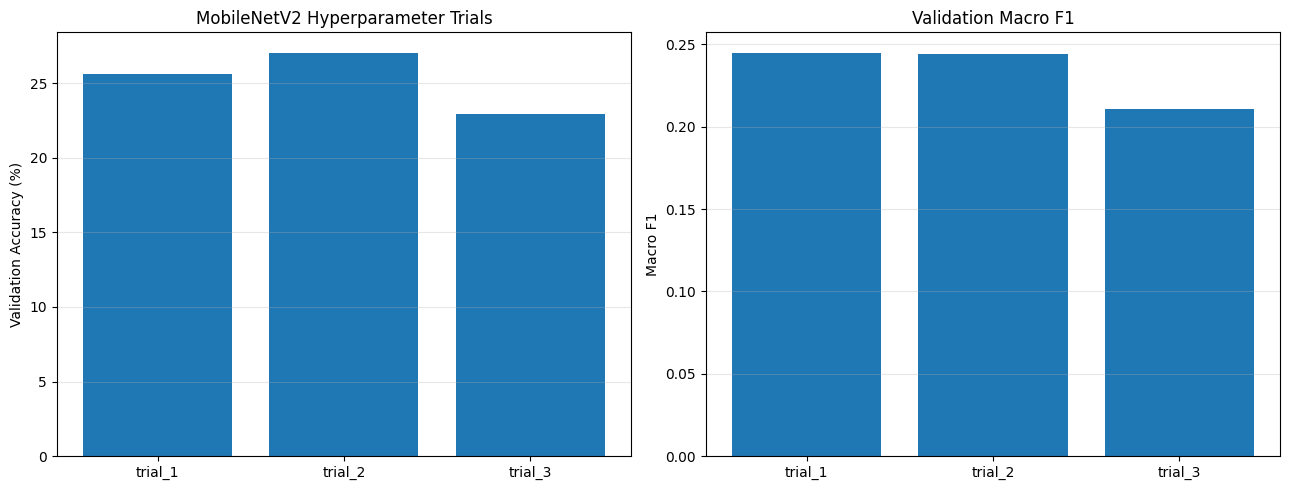

In [4]:

import pandas as pd
import matplotlib.pyplot as plt

tuning_df = pd.DataFrame([
    {
        "Trial": r["params"]["name"],
        "Validation Accuracy": r["val_accuracy"],
        "Validation Macro F1": r["val_macro_f1"],
        "Head LR": r["params"]["lr"],
        "Backbone LR": r["params"]["unfreeze_lr"],
        "Weight Decay": r["params"]["weight_decay"],
        "Dropout": r["params"]["dropout"]
    }
    for r in trial_results
])

display(tuning_df)

tuning_df.to_csv(
    RUN_DIR / "hyperparameter_trials.csv",
    index=False
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].bar(
    tuning_df["Trial"],
    tuning_df["Validation Accuracy"]
)
axes[0].set_title("MobileNetV2 Hyperparameter Trials")
axes[0].set_ylabel("Validation Accuracy (%)")
axes[0].grid(axis="y", alpha=0.3)

axes[1].bar(
    tuning_df["Trial"],
    tuning_df["Validation Macro F1"]
)
axes[1].set_title("Validation Macro F1")
axes[1].set_ylabel("Macro F1")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(
    RUN_DIR / "hyperparameter_visual_comparison.png",
    dpi=200
)
plt.show()


**Extract and cache temporal video features**

In [5]:

import torch
from torch.utils.data import DataLoader

from src.data.dataset import MMActMultimodalDataset
from src.models.fusion_model import MultimodalHARModel
from src.config import VERIFIED_TARGET_CLASSES

FINAL_CHECKPOINT = (
    FINAL_MOBILENET_DIR
    / "checkpoints"
    / "best_model_mobilenet_v2.pth"
)

assert FINAL_CHECKPOINT.exists(), "Fine-tuned MobileNetV2 checkpoint missing."

checkpoint = torch.load(
    FINAL_CHECKPOINT,
    map_location="cpu"
)

# Rebuild exactly the trained project architecture.
feature_model = MultimodalHARModel(
    num_classes=10,
    video_channels=3,
    sensor_channels=9,
    video_embed_dim=128,
    sensor_embed_dim=128,
    fusion_hidden_dim=128,
    dropout=BEST_PARAMS["dropout"],
    mode="video_only",
    video_backbone="mobilenet_v2",
    sensor_backbone="inception_time",
    pretrained_video=False
)

feature_model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

feature_model.to(DEVICE).eval()

video_branch = feature_model.video_branch

for parameter in video_branch.parameters():
    parameter.requires_grad_(False)

FEATURE_DIR = RUN_DIR / "cached_temporal_features"
FEATURE_DIR.mkdir(parents=True, exist_ok=True)

def extract_features(samples, split_name):
    dataset = MMActMultimodalDataset(
        samples,
        cache_dir=CACHE_DIR / split_name,
        enable_cache=True,
        mode="video_only"
    )

    loader = DataLoader(
        dataset,
        batch_size=8,
        shuffle=False,
        num_workers=2,
        pin_memory=True
    )

    features_all = []
    labels_all = []
    ids_all = []

    with torch.inference_mode():
        for videos, sensors, labels, sample_ids in loader:
            videos = videos.to(DEVICE, non_blocking=True)

            b, c, t, h, w = videos.shape

            frames = (
                videos.permute(0, 2, 1, 3, 4)
                .reshape(b * t, c, h, w)
            )

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):
                frame_maps = video_branch.backbone(frames)
                frame_features = (
                    video_branch.backbone_pool(frame_maps)
                    .flatten(1)
                )

            sequence = frame_features.view(
                b, t, 1280
            ).cpu().half()

            features_all.append(sequence)
            labels_all.append(labels.cpu())
            ids_all.extend(list(sample_ids))

    X = torch.cat(features_all, dim=0)
    y = torch.cat(labels_all, dim=0).long()

    assert len(ids_all) == len(set(ids_all)), (
        f"Duplicate sample IDs in {split_name} features."
    )

    save_path = FEATURE_DIR / f"{split_name}.pt"

    torch.save(
        {
            "features": X,
            "labels": y,
            "sample_ids": ids_all
        },
        save_path
    )

    print(
        split_name,
        "Features:", tuple(X.shape),
        "Samples:", len(y)
    )

    return X, y, ids_all


X_train, y_train, train_ids = extract_features(
    train_samples, "train"
)

X_val, y_val, val_ids = extract_features(
    val_samples, "val"
)

assert X_train.shape[1:] == (16, 1280)
assert X_val.shape[1:] == (16, 1280)

assert len(X_train) == 3795
assert len(X_val) == 780

print("Temporal features extracted successfully.")


[MobileNetV2VideoBranch] Initialized unweighted torchvision MobileNetV2 architecture.
train Features: (3795, 16, 1280) Samples: 3795
val Features: (780, 16, 1280) Samples: 780
Temporal features extracted successfully.


**Train BiLSTM and TCN temporal heads**


TRAINING: BILSTM


/tmp/ipykernel_47/2245605455.py:267: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=True)


Epoch 01/12 | Train Acc 20.37% | Val Acc 19.87% | Val F1 0.1601 | Val Loss 1.9635
Epoch 02/12 | Train Acc 27.09% | Val Acc 23.33% | Val F1 0.1848 | Val Loss 1.9646
Epoch 03/12 | Train Acc 31.33% | Val Acc 24.74% | Val F1 0.2109 | Val Loss 1.8906
Epoch 04/12 | Train Acc 35.55% | Val Acc 27.95% | Val F1 0.2735 | Val Loss 1.9478
Epoch 05/12 | Train Acc 39.82% | Val Acc 30.26% | Val F1 0.2858 | Val Loss 2.0485
Epoch 06/12 | Train Acc 41.92% | Val Acc 30.51% | Val F1 0.2737 | Val Loss 1.8620
Epoch 07/12 | Train Acc 47.40% | Val Acc 28.46% | Val F1 0.2791 | Val Loss 2.0260
Epoch 08/12 | Train Acc 52.02% | Val Acc 30.26% | Val F1 0.2970 | Val Loss 2.0645
Epoch 09/12 | Train Acc 55.07% | Val Acc 30.51% | Val F1 0.3005 | Val Loss 2.1408
Epoch 10/12 | Train Acc 59.55% | Val Acc 29.36% | Val F1 0.2954 | Val Loss 2.2503
Epoch 11/12 | Train Acc 64.77% | Val Acc 31.41% | Val F1 0.3216 | Val Loss 2.2672
Epoch 12/12 | Train Acc 65.67% | Val Acc 31.92% | Val F1 0.3088 | Val Loss 2.4568
ROC/PR warning: 

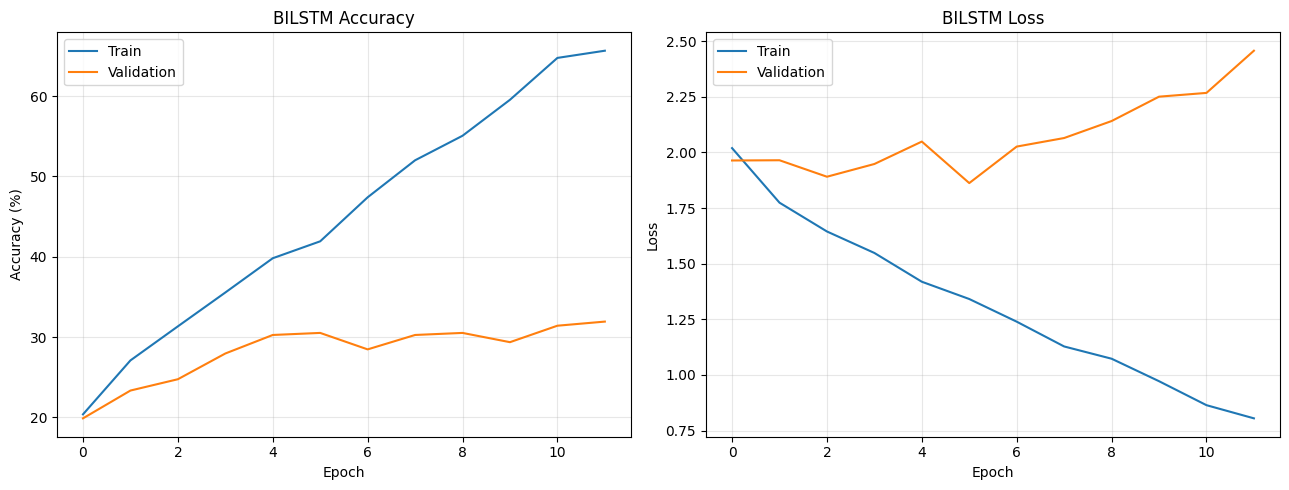

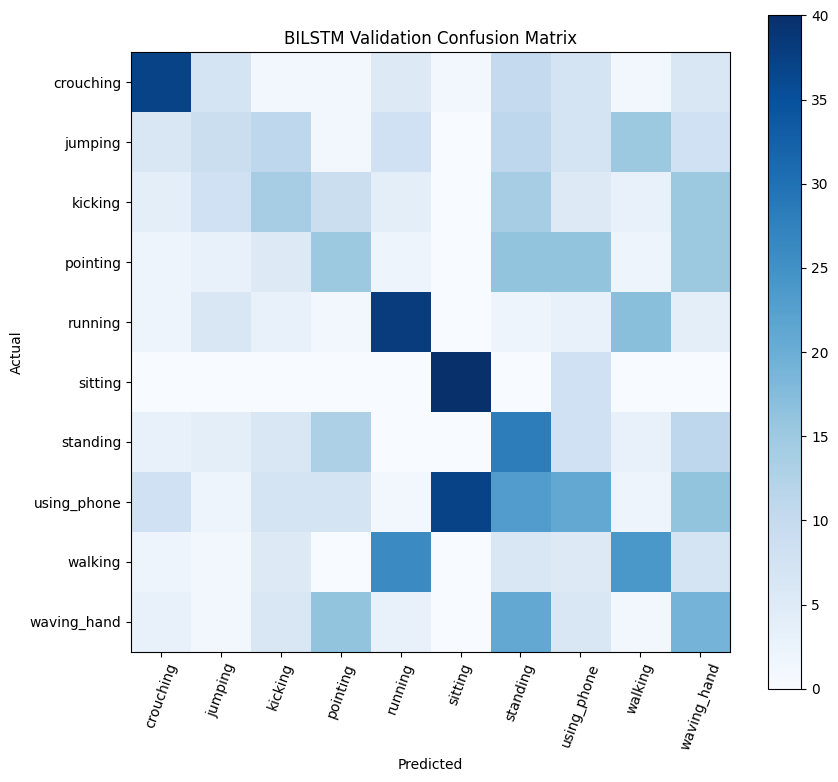

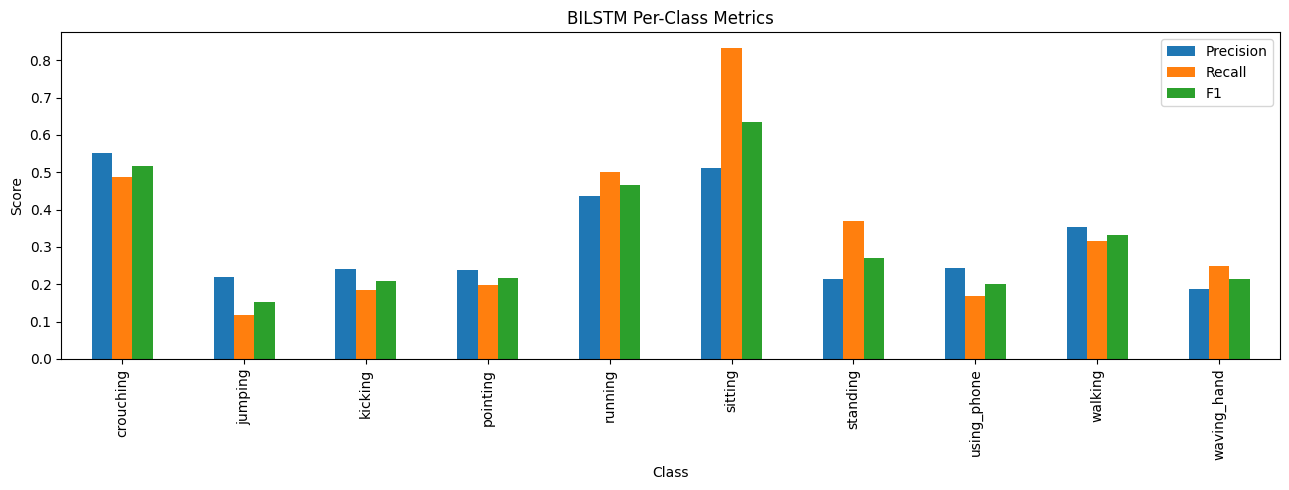

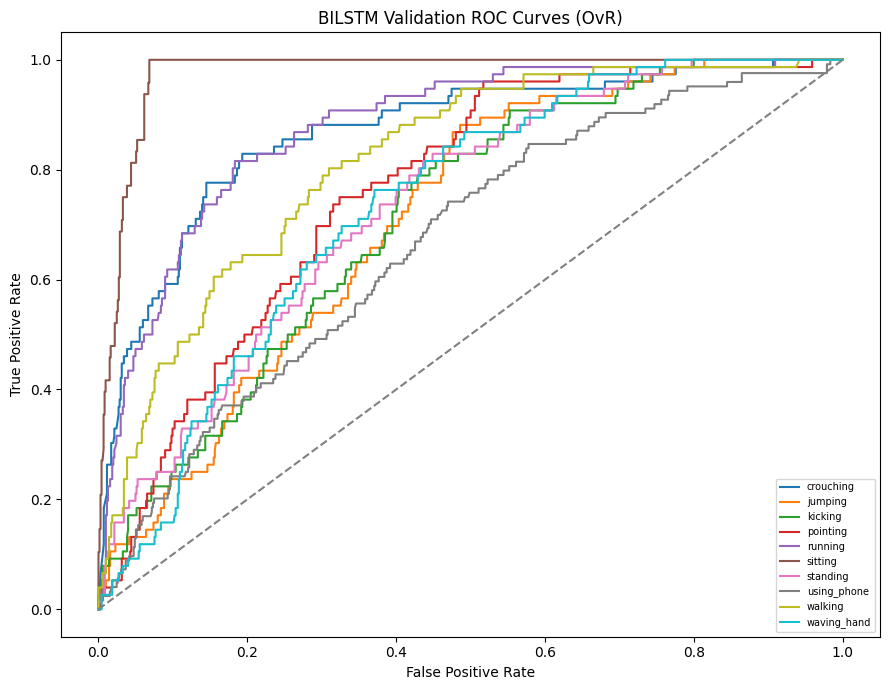

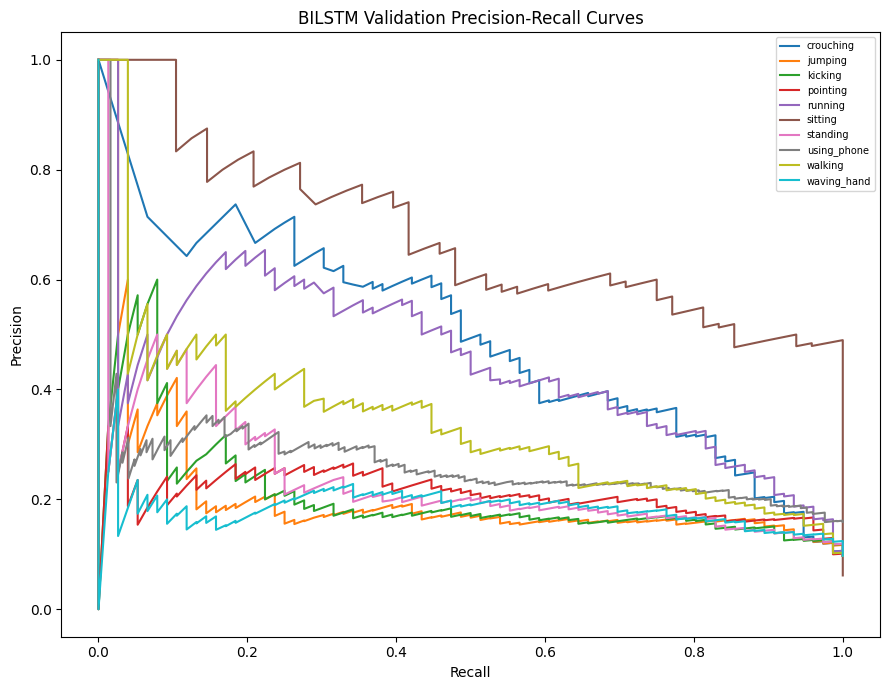


RESULT: BILSTM
{
  "accuracy": 0.3141025641025641,
  "macro_precision": 0.3199814164426753,
  "macro_recall": 0.34237408036219585,
  "macro_f1": 0.32158435368072963,
  "per_class": {
    "crouching": {
      "precision": 0.5522388059701493,
      "recall": 0.4868421052631579,
      "f1": 0.5174825174825175,
      "support": 76.0
    },
    "jumping": {
      "precision": 0.21951219512195122,
      "recall": 0.11842105263157894,
      "f1": 0.15384615384615385,
      "support": 76.0
    },
    "kicking": {
      "precision": 0.2413793103448276,
      "recall": 0.18421052631578946,
      "f1": 0.208955223880597,
      "support": 76.0
    },
    "pointing": {
      "precision": 0.23809523809523808,
      "recall": 0.19736842105263158,
      "f1": 0.2158273381294964,
      "support": 76.0
    },
    "running": {
      "precision": 0.4367816091954023,
      "recall": 0.5,
      "f1": 0.4662576687116564,
      "support": 76.0
    },
    "sitting": {
      "precision": 0.5128205128205128,
  

/tmp/ipykernel_47/2245605455.py:267: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=True)


Epoch 01/12 | Train Acc 18.92% | Val Acc 19.87% | Val F1 0.1405 | Val Loss 1.9674
Epoch 02/12 | Train Acc 25.35% | Val Acc 22.56% | Val F1 0.1829 | Val Loss 1.8977
Epoch 03/12 | Train Acc 29.54% | Val Acc 25.38% | Val F1 0.1965 | Val Loss 1.9035
Epoch 04/12 | Train Acc 33.20% | Val Acc 26.28% | Val F1 0.2279 | Val Loss 1.9617
Epoch 05/12 | Train Acc 37.36% | Val Acc 28.85% | Val F1 0.2808 | Val Loss 1.9504
Epoch 06/12 | Train Acc 41.55% | Val Acc 30.77% | Val F1 0.2890 | Val Loss 1.8539
Epoch 07/12 | Train Acc 47.14% | Val Acc 32.95% | Val F1 0.2868 | Val Loss 1.8902
Epoch 08/12 | Train Acc 50.91% | Val Acc 33.46% | Val F1 0.3352 | Val Loss 1.9443
Epoch 09/12 | Train Acc 54.49% | Val Acc 34.74% | Val F1 0.3432 | Val Loss 2.1488
Epoch 10/12 | Train Acc 58.87% | Val Acc 33.59% | Val F1 0.3260 | Val Loss 2.3329
Epoch 11/12 | Train Acc 60.34% | Val Acc 32.31% | Val F1 0.3204 | Val Loss 2.1581
Epoch 12/12 | Train Acc 61.58% | Val Acc 31.03% | Val F1 0.3102 | Val Loss 2.3444
ROC/PR warning: 

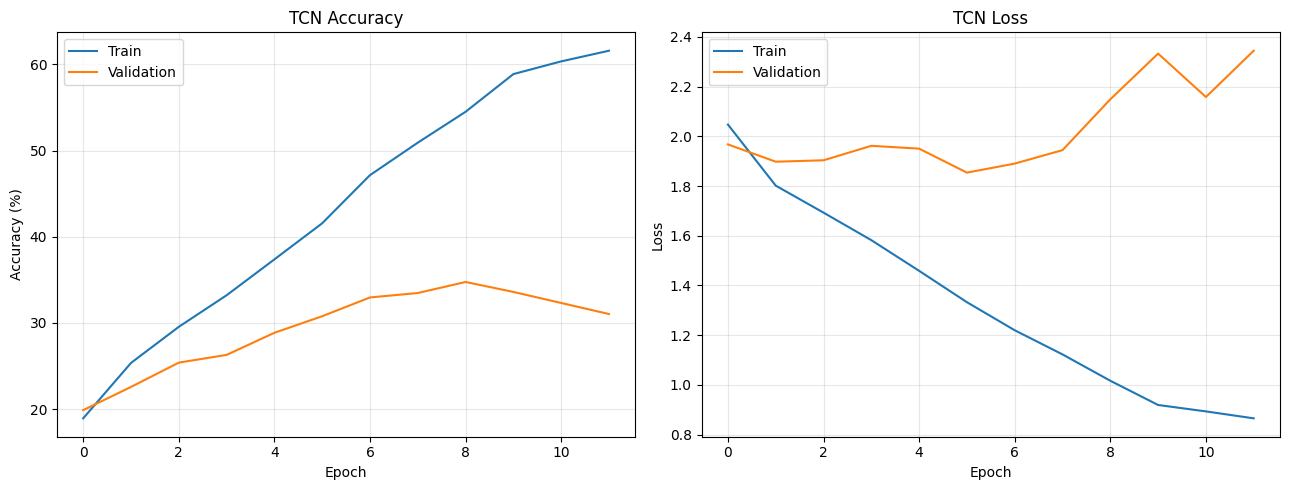

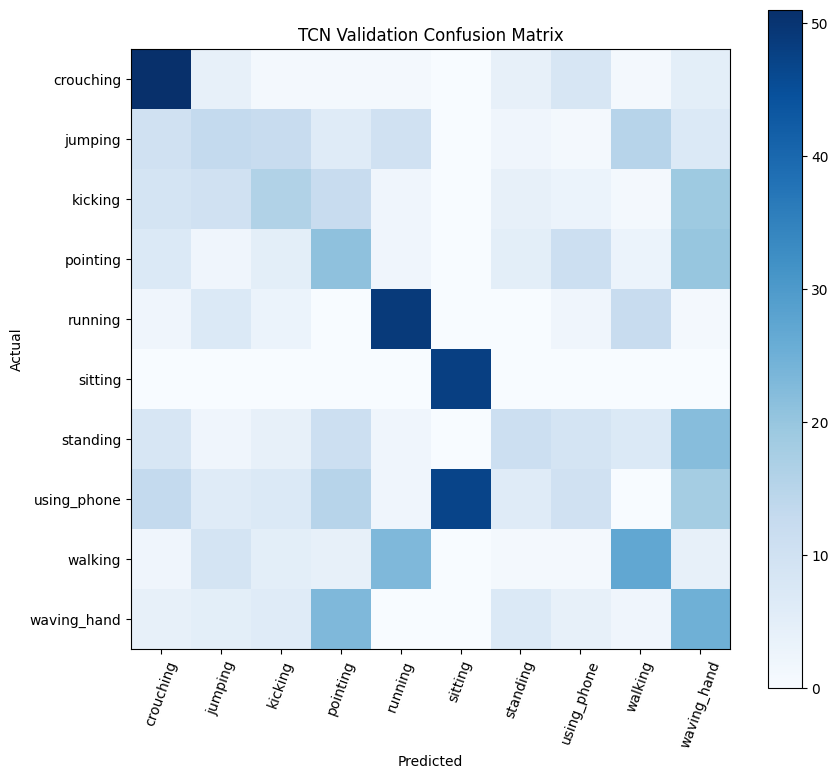

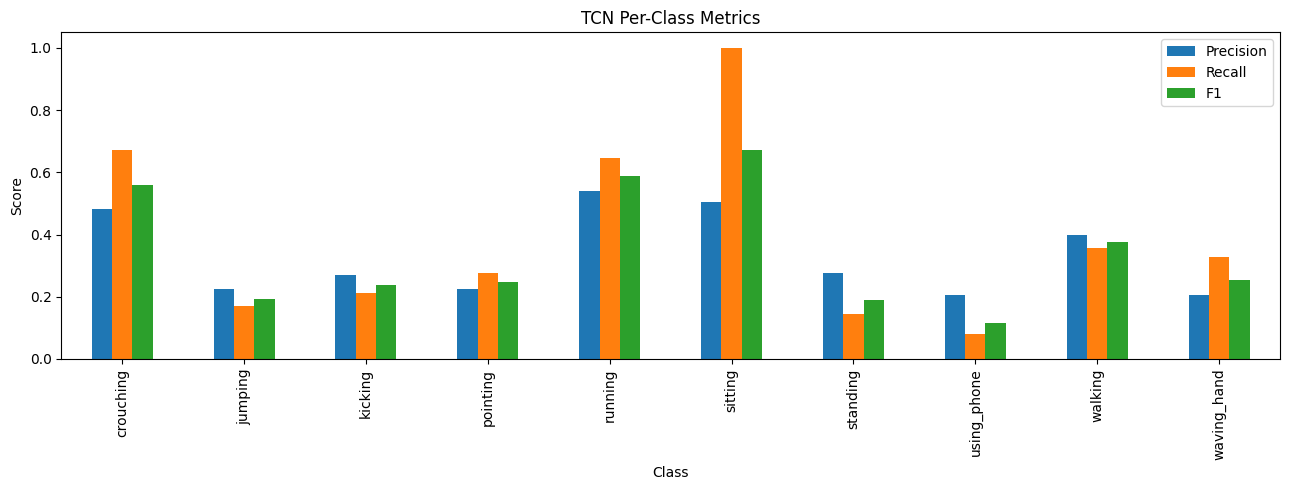

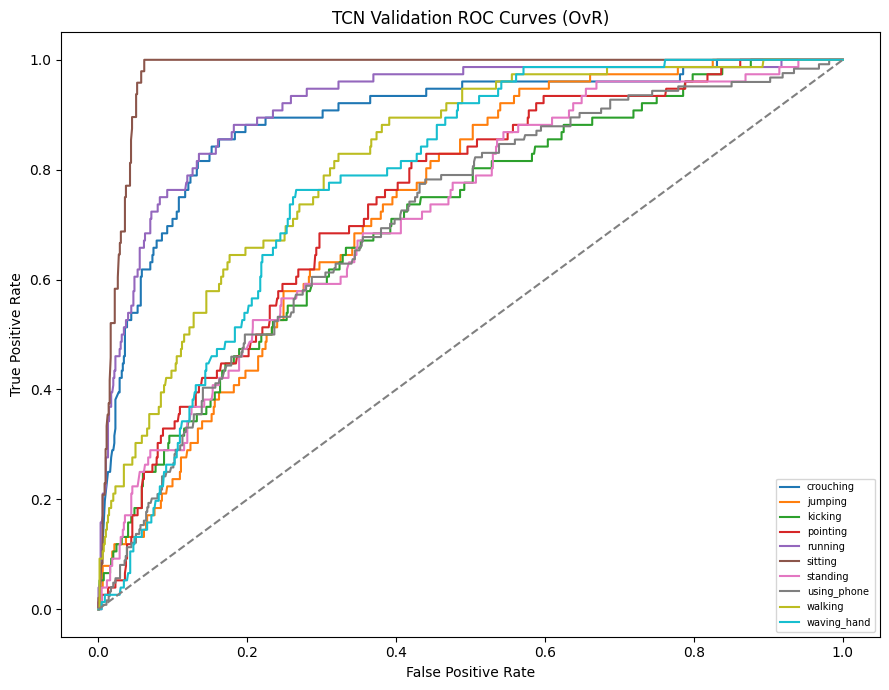

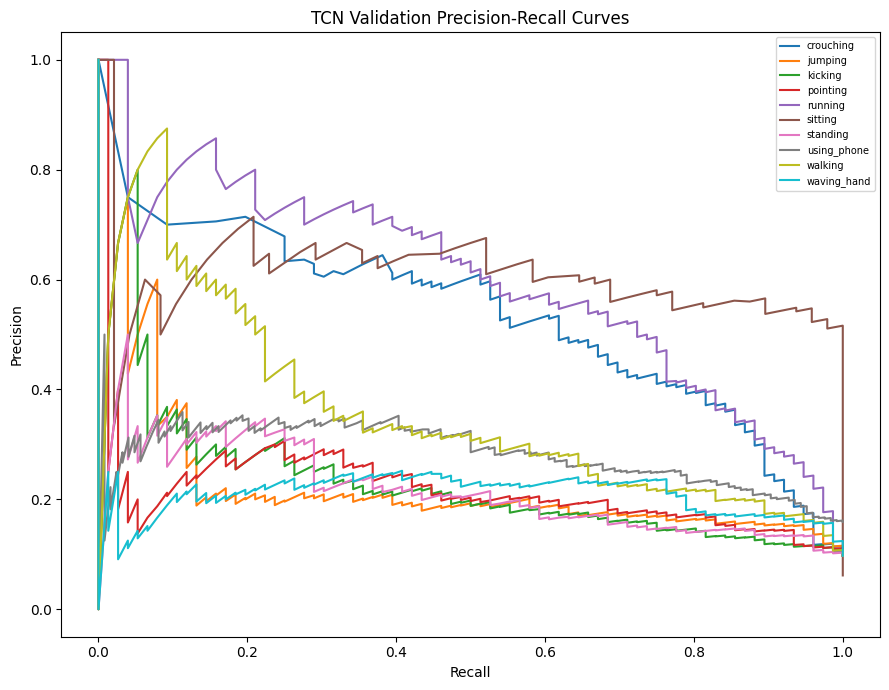


RESULT: TCN
{
  "accuracy": 0.3474358974358974,
  "macro_precision": 0.3328739621583733,
  "macro_recall": 0.3883276740237691,
  "macro_f1": 0.34322513923450615,
  "per_class": {
    "crouching": {
      "precision": 0.4811320754716981,
      "recall": 0.6710526315789473,
      "f1": 0.5604395604395604,
      "support": 76.0
    },
    "jumping": {
      "precision": 0.22413793103448276,
      "recall": 0.17105263157894737,
      "f1": 0.19402985074626866,
      "support": 76.0
    },
    "kicking": {
      "precision": 0.2711864406779661,
      "recall": 0.21052631578947367,
      "f1": 0.23703703703703705,
      "support": 76.0
    },
    "pointing": {
      "precision": 0.22580645161290322,
      "recall": 0.27631578947368424,
      "f1": 0.2485207100591716,
      "support": 76.0
    },
    "running": {
      "precision": 0.5384615384615384,
      "recall": 0.6447368421052632,
      "f1": 0.5868263473053892,
      "support": 76.0
    },
    "sitting": {
      "precision": 0.5052631

In [6]:

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    classification_report,
    roc_curve,
    precision_recall_curve
)

CLASSES = VERIFIED_TARGET_CLASSES
NUM_CLASSES = len(CLASSES)

TEMPORAL_DIR = RUN_DIR / "temporal_heads"
TEMPORAL_DIR.mkdir(parents=True, exist_ok=True)


class FeatureDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx], idx


class TCNResidualBlock(nn.Module):
    def __init__(self, channels, dilation, dropout=0.15):
        super().__init__()

        self.network = nn.Sequential(
            nn.Conv1d(
                channels, channels,
                kernel_size=3,
                padding=dilation,
                dilation=dilation
            ),
            nn.GroupNorm(8, channels),
            nn.GELU(),
            nn.Dropout(dropout),

            nn.Conv1d(
                channels, channels,
                kernel_size=3,
                padding=dilation,
                dilation=dilation
            ),
            nn.GroupNorm(8, channels)
        )

        self.activation = nn.GELU()

    def forward(self, x):
        return self.activation(x + self.network(x))


class TemporalClassifier(nn.Module):
    def __init__(self, kind, num_classes=10):
        super().__init__()

        self.kind = kind

        if kind == "bilstm":
            self.project = nn.Sequential(
                nn.Linear(1280, 256),
                nn.LayerNorm(256),
                nn.GELU(),
                nn.Dropout(0.25)
            )

            self.temporal = nn.LSTM(
                input_size=256,
                hidden_size=128,
                num_layers=1,
                batch_first=True,
                bidirectional=True
            )

            out_dim = 256

        elif kind == "tcn":
            self.project = nn.Sequential(
                nn.Linear(1280, 128),
                nn.LayerNorm(128),
                nn.GELU()
            )

            self.temporal = nn.Sequential(
                TCNResidualBlock(128, dilation=1),
                TCNResidualBlock(128, dilation=2),
                TCNResidualBlock(128, dilation=4)
            )

            out_dim = 128

        else:
            raise ValueError("kind must be bilstm or tcn")

        self.classifier = nn.Sequential(
            nn.LayerNorm(out_dim * 2),
            nn.Dropout(0.30),
            nn.Linear(out_dim * 2, 128),
            nn.GELU(),
            nn.Dropout(0.25),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.project(x)

        if self.kind == "bilstm":
            x, _ = self.temporal(x)
        else:
            x = self.temporal(x.transpose(1, 2))
            x = x.transpose(1, 2)

        pooled = torch.cat(
            [x.mean(dim=1), x.max(dim=1).values],
            dim=1
        )

        return self.classifier(pooled)


def calculate_metrics(y_true, probabilities):
    y_pred = probabilities.argmax(axis=1)

    metrics = {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "macro_precision": float(
            precision_score(y_true, y_pred, average="macro", zero_division=0)
        ),
        "macro_recall": float(
            recall_score(y_true, y_pred, average="macro", zero_division=0)
        ),
        "macro_f1": float(
            f1_score(y_true, y_pred, average="macro", zero_division=0)
        )
    }

    onehot = np.eye(NUM_CLASSES)[y_true]

    try:
        metrics["roc_auc_ovr"] = float(
            roc_auc_score(
                y_true,
                probabilities,
                multi_class="ovr",
                average="macro",
                labels=np.arange(NUM_CLASSES)
            )
        )

        metrics["macro_ap"] = float(
            average_precision_score(
                onehot,
                probabilities,
                average="macro"
            )
        )
    except ValueError as exc:
        print("ROC/PR warning:", exc)

    report = classification_report(
        y_true,
        y_pred,
        labels=np.arange(NUM_CLASSES),
        target_names=CLASSES,
        output_dict=True,
        zero_division=0
    )

    metrics["per_class"] = {
        cls: {
            "precision": report[cls]["precision"],
            "recall": report[cls]["recall"],
            "f1": report[cls]["f1-score"],
            "support": report[cls]["support"]
        }
        for cls in CLASSES
    }

    return metrics, y_pred


def train_temporal_model(
    kind,
    epochs=12,
    patience=4,
    batch_size=128
):
    print("\n" + "=" * 65)
    print("TRAINING:", kind.upper())
    print("=" * 65)

    out_dir = TEMPORAL_DIR / kind
    out_dir.mkdir(parents=True, exist_ok=True)

    train_ds = FeatureDataset(X_train, y_train)
    val_ds = FeatureDataset(X_val, y_val)

    train_loader = DataLoader(
        train_ds,
        batch_size=batch_size,
        shuffle=True,
        num_workers=0,
        pin_memory=True
    )

    val_loader = DataLoader(
        val_ds,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0,
        pin_memory=True
    )

    counts = np.bincount(
        y_train.numpy(),
        minlength=NUM_CLASSES
    )

    weights = counts.sum() / (
        NUM_CLASSES * np.maximum(counts, 1)
    )

    weights = weights / weights.mean()

    class_weights = torch.tensor(
        weights,
        dtype=torch.float32,
        device=DEVICE
    )

    criterion = nn.CrossEntropyLoss(weight=class_weights)

    model = TemporalClassifier(kind).to(DEVICE)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=8e-4,
        weight_decay=1e-4
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="max",
        factor=0.5,
        patience=2
    )

    scaler = torch.cuda.amp.GradScaler(enabled=True)

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": [],
        "val_macro_f1": []
    }

    best_f1 = -1
    stale = 0

    for epoch in range(1, epochs + 1):

        model.train()
        running_loss = 0
        train_correct = 0
        train_total = 0

        for xb, yb, _ in train_loader:
            xb = xb.to(DEVICE, non_blocking=True).float()
            yb = yb.to(DEVICE, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):
                logits = model(xb)
                loss = criterion(logits, yb)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            running_loss += loss.item() * len(yb)
            train_correct += (
                logits.detach().argmax(1) == yb
            ).sum().item()

            train_total += len(yb)

        train_loss = running_loss / train_total
        train_acc = 100 * train_correct / train_total

        model.eval()

        val_loss_sum = 0
        all_probs = []
        all_labels = []

        with torch.inference_mode():
            for xb, yb, _ in val_loader:
                xb = xb.to(DEVICE, non_blocking=True).float()
                yb = yb.to(DEVICE, non_blocking=True)

                with torch.autocast(
                    device_type="cuda",
                    dtype=torch.float16
                ):
                    logits = model(xb)
                    loss = criterion(logits, yb)

                val_loss_sum += loss.item() * len(yb)
                all_probs.append(
                    torch.softmax(logits, dim=1).cpu().numpy()
                )
                all_labels.append(yb.cpu().numpy())

        probabilities = np.concatenate(all_probs)
        y_true = np.concatenate(all_labels)
        y_pred = probabilities.argmax(axis=1)

        val_loss = val_loss_sum / len(y_true)
        val_acc = 100 * accuracy_score(y_true, y_pred)
        val_f1 = f1_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        )

        history["train_loss"].append(float(train_loss))
        history["val_loss"].append(float(val_loss))
        history["train_acc"].append(float(train_acc))
        history["val_acc"].append(float(val_acc))
        history["val_macro_f1"].append(float(val_f1))

        scheduler.step(val_f1)

        print(
            f"Epoch {epoch:02d}/{epochs} | "
            f"Train Acc {train_acc:.2f}% | "
            f"Val Acc {val_acc:.2f}% | "
            f"Val F1 {val_f1:.4f} | "
            f"Val Loss {val_loss:.4f}"
        )

        if val_f1 > best_f1:
            best_f1 = val_f1
            stale = 0

            torch.save(
                {
                    "model_state_dict": model.state_dict(),
                    "kind": kind,
                    "epoch": epoch,
                    "best_val_macro_f1": best_f1
                },
                out_dir / "best_model.pth"
            )
        else:
            stale += 1

        if stale >= patience:
            print("Early stopping.")
            break

    # Restore the best validation checkpoint.
    saved = torch.load(
        out_dir / "best_model.pth",
        map_location=DEVICE
    )

    model.load_state_dict(saved["model_state_dict"])
    model.eval()

    # Final validation predictions for the selected checkpoint.
    all_probs = []
    all_labels = []
    all_indices = []

    with torch.inference_mode():
        for xb, yb, idx in val_loader:
            xb = xb.to(DEVICE).float()

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):
                logits = model(xb)

            all_probs.append(
                torch.softmax(logits, dim=1).cpu().numpy()
            )
            all_labels.append(yb.numpy())
            all_indices.append(idx.numpy())

    probs = np.concatenate(all_probs)
    y_true = np.concatenate(all_labels)
    indices = np.concatenate(all_indices)

    order = np.argsort(indices)
    probs = probs[order]
    y_true = y_true[order]

    metrics, predictions = calculate_metrics(y_true, probs)

    with open(out_dir / "validation_metrics.json", "w") as f:
        json.dump(metrics, f, indent=2)

    with open(out_dir / "history.json", "w") as f:
        json.dump(history, f, indent=2)

    pred_df = pd.DataFrame({
        "sample_id": val_ids,
        "ground_truth": [CLASSES[i] for i in y_true],
        "predicted": [CLASSES[i] for i in predictions],
        "confidence": probs.max(axis=1)
    })

    for i, cls in enumerate(CLASSES):
        pred_df[f"prob_{cls}"] = probs[:, i]

    pred_df.to_csv(
        out_dir / "validation_predictions.csv",
        index=False
    )

    # Epoch-wise visualizations.
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    axes[0].plot(history["train_acc"], label="Train")
    axes[0].plot(history["val_acc"], label="Validation")
    axes[0].set_title(f"{kind.upper()} Accuracy")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Accuracy (%)")
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    axes[1].plot(history["train_loss"], label="Train")
    axes[1].plot(history["val_loss"], label="Validation")
    axes[1].set_title(f"{kind.upper()} Loss")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Loss")
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig(out_dir / "training_curves.png", dpi=200)
    plt.show()

    # Confusion matrix.
    cm = confusion_matrix(
        y_true, predictions,
        labels=np.arange(NUM_CLASSES)
    )

    plt.figure(figsize=(9, 8))
    plt.imshow(cm, cmap="Blues")
    plt.xticks(range(NUM_CLASSES), CLASSES, rotation=70)
    plt.yticks(range(NUM_CLASSES), CLASSES)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(f"{kind.upper()} Validation Confusion Matrix")
    plt.colorbar()
    plt.tight_layout()
    plt.savefig(out_dir / "confusion_matrix.png", dpi=200)
    plt.show()

    # Precision / Recall / F1 comparison.
    per_class = metrics["per_class"]

    metric_df = pd.DataFrame({
        "Class": CLASSES,
        "Precision": [per_class[c]["precision"] for c in CLASSES],
        "Recall": [per_class[c]["recall"] for c in CLASSES],
        "F1": [per_class[c]["f1"] for c in CLASSES]
    })

    metric_df.set_index("Class").plot(
        kind="bar",
        figsize=(13, 5)
    )
    plt.title(f"{kind.upper()} Per-Class Metrics")
    plt.ylabel("Score")
    plt.tight_layout()
    plt.savefig(out_dir / "per_class_metrics.png", dpi=200)
    plt.show()

    # Multiclass One-vs-Rest ROC.
    onehot = np.eye(NUM_CLASSES)[y_true]

    plt.figure(figsize=(9, 7))

    for i, cls in enumerate(CLASSES):
        fpr, tpr, _ = roc_curve(onehot[:, i], probs[:, i])
        plt.plot(fpr, tpr, label=cls)

    plt.plot([0, 1], [0, 1], "--", color="gray")
    plt.title(f"{kind.upper()} Validation ROC Curves (OvR)")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend(fontsize=7)
    plt.tight_layout()
    plt.savefig(out_dir / "roc_curves.png", dpi=200)
    plt.show()

    # Multiclass Precision-Recall.
    plt.figure(figsize=(9, 7))

    for i, cls in enumerate(CLASSES):
        precision, recall, _ = precision_recall_curve(
            onehot[:, i], probs[:, i]
        )
        plt.plot(recall, precision, label=cls)

    plt.title(f"{kind.upper()} Validation Precision-Recall Curves")
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.legend(fontsize=7)
    plt.tight_layout()
    plt.savefig(out_dir / "precision_recall_curves.png", dpi=200)
    plt.show()

    print("\nRESULT:", kind.upper())
    print(json.dumps(metrics, indent=2))

    return {
        "kind": kind,
        "metrics": metrics,
        "checkpoint": str(out_dir / "best_model.pth"),
        "history": history
    }


bilstm_result = train_temporal_model(
    kind="bilstm",
    epochs=12,
    patience=4
)

tcn_result = train_temporal_model(
    kind="tcn",
    epochs=12,
    patience=4
)


**Consolidated visual comparison**

,model,validation_accuracy,validation_macro_f1
0,MobileNetV2 Original,35.26%,0.3492
1,MobileNetV2 + TCN,34.74%,0.3432
2,MobileNetV2 + BiLSTM,31.41%,0.3216
3,MobileNetV2 Fine-tuning V2,30.13%,0.2932


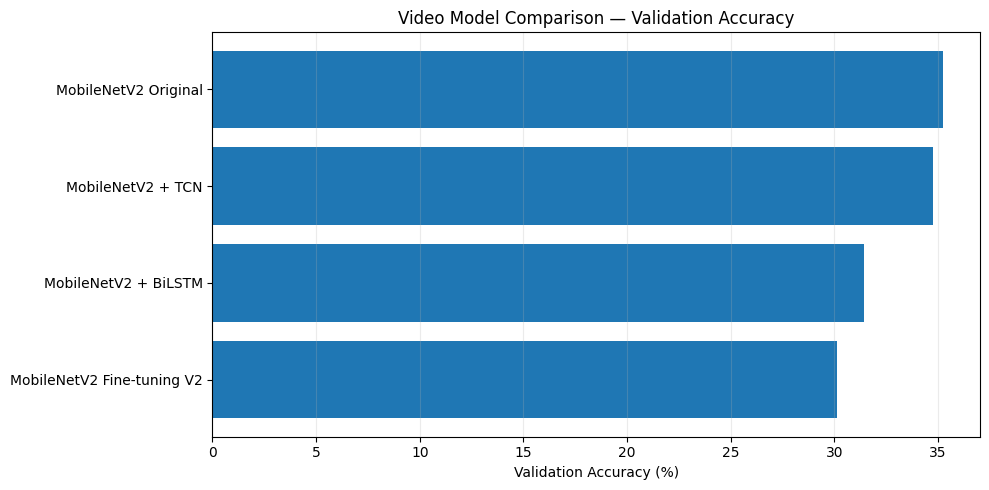

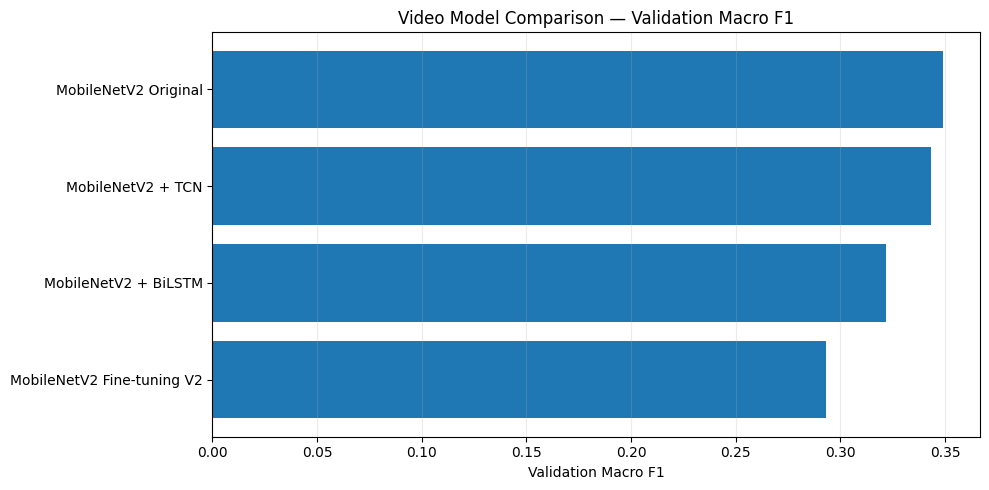

Saved comparison files to: /kaggle/working/HAR-MMAct/outputs/video_improvement_runs/20261116_091302/final_comparison

Best model by validation Macro F1:
{'model': 'MobileNetV2 Original', 'validation_accuracy': 0.3526, 'validation_macro_f1': 0.3492}


In [7]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Actual validation results from completed experiments
results = [
    {
        "model": "MobileNetV2 Original",
        "validation_accuracy": 0.3526,
        "validation_macro_f1": 0.3492
    },
    {
        "model": "MobileNetV2 + TCN",
        "validation_accuracy": 0.3474359,
        "validation_macro_f1": 0.3432251
    },
    {
        "model": "MobileNetV2 + BiLSTM",
        "validation_accuracy": 0.3141026,
        "validation_macro_f1": 0.3215844
    },
    {
        "model": "MobileNetV2 Fine-tuning V2",
        "validation_accuracy": 0.3012821,
        "validation_macro_f1": 0.2932358
    }
]

df = pd.DataFrame(results)
df = df.sort_values(
    "validation_macro_f1",
    ascending=False
).reset_index(drop=True)

# Save results
OUTPUT_DIR = Path(
    "/kaggle/working/HAR-MMAct/outputs/"
    "video_improvement_runs/20261116_091302/final_comparison"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

df.to_csv(
    OUTPUT_DIR / "video_model_validation_comparison.csv",
    index=False
)

display(
    df.style.format({
        "validation_accuracy": "{:.2%}",
        "validation_macro_f1": "{:.4f}"
    })
)

# Chart 1: Validation accuracy
plt.figure(figsize=(10, 5))
plt.barh(
    df["model"],
    df["validation_accuracy"] * 100
)
plt.xlabel("Validation Accuracy (%)")
plt.title("Video Model Comparison — Validation Accuracy")
plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "validation_accuracy_comparison.png",
    dpi=180
)
plt.show()

# Chart 2: Validation Macro F1
plt.figure(figsize=(10, 5))
plt.barh(
    df["model"],
    df["validation_macro_f1"]
)
plt.xlabel("Validation Macro F1")
plt.title("Video Model Comparison — Validation Macro F1")
plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "validation_macro_f1_comparison.png",
    dpi=180
)
plt.show()

print("Saved comparison files to:", OUTPUT_DIR)
print("\nBest model by validation Macro F1:")
print(df.iloc[0].to_dict())

**Correct ROC-AUC and PR**

In [9]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve,
    auc
)

# Existing trained models from Cell 6
models = {
    "BiLSTM": bilstm_result["model"],
    "TCN": tcn_result["model"]
}

CLASS_NAMES = list(CLASSES)
NUM_CLASSES = len(CLASS_NAMES)

OUTPUT_DIR = Path(
    "/kaggle/working/HAR-MMAct/outputs/"
    "video_temporal_runs/20261116_temporal_heads/roc_pr_validation"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

all_metrics = []

for model_name, model in models.items():

    model.eval()
    all_probs = []
    all_labels = []

    # Generate validation probabilities
    with torch.inference_mode():
        for xb, yb in val_loader:
            xb = xb.to(DEVICE)

            logits = model(xb)
            probabilities = torch.softmax(
                logits.float(), dim=1
            )

            all_probs.append(probabilities.cpu().numpy())
            all_labels.extend(yb.numpy())

    y_score = np.concatenate(all_probs, axis=0)
    y_true = np.asarray(all_labels, dtype=np.int64)

    y_true_bin = label_binarize(
        y_true,
        classes=np.arange(NUM_CLASSES)
    )

    # Probability integrity checks
    assert y_score.shape == (len(y_true), NUM_CLASSES)
    assert np.all(np.isfinite(y_score))
    assert np.allclose(
        y_score.sum(axis=1), 1.0, atol=1e-4
    )

    # Multiclass metrics
    macro_auc = roc_auc_score(
        y_true,
        y_score,
        multi_class="ovr",
        average="macro"
    )

    macro_ap = average_precision_score(
        y_true_bin,
        y_score,
        average="macro"
    )

    all_metrics.append({
        "model": model_name,
        "validation_ROC_AUC_OvR_macro": float(macro_auc),
        "validation_macro_average_precision": float(macro_ap)
    })

    # ROC curves
    plt.figure(figsize=(9, 7))

    for i, class_name in enumerate(CLASS_NAMES):
        fpr, tpr, _ = roc_curve(
            y_true_bin[:, i], y_score[:, i]
        )
        class_auc = auc(fpr, tpr)

        plt.plot(
            fpr, tpr,
            label=f"{class_name} (AUC={class_auc:.3f})"
        )

    plt.plot([0, 1], [0, 1], linestyle="--")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"{model_name} — Validation ROC Curves")
    plt.legend(fontsize=8, loc="lower right")
    plt.grid(alpha=0.2)
    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR / f"{model_name.lower()}_roc.png",
        dpi=160
    )
    plt.show()
    plt.close()

    # Precision-Recall curves
    plt.figure(figsize=(9, 7))

    for i, class_name in enumerate(CLASS_NAMES):
        precision, recall, _ = precision_recall_curve(
            y_true_bin[:, i], y_score[:, i]
        )

        ap = average_precision_score(
            y_true_bin[:, i], y_score[:, i]
        )

        plt.plot(
            recall, precision,
            label=f"{class_name} (AP={ap:.3f})"
        )

    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title(f"{model_name} — Validation PR Curves")
    plt.legend(fontsize=8, loc="best")
    plt.grid(alpha=0.2)
    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR / f"{model_name.lower()}_pr.png",
        dpi=160
    )
    plt.show()
    plt.close()

# Save metrics
metrics_df = pd.DataFrame(all_metrics)

metrics_df.to_csv(
    OUTPUT_DIR / "roc_pr_validation_metrics.csv",
    index=False
)

with open(
    OUTPUT_DIR / "roc_pr_validation_metrics.json", "w"
) as f:
    json.dump(all_metrics, f, indent=2)

display(metrics_df)

print("ROC/PR validation evaluation completed.")
print("Saved to:", OUTPUT_DIR)
print("Validation samples:", len(y_true))

KeyError: 'model'

In [10]:
for name, result in [
    ("bilstm_result", bilstm_result),
    ("tcn_result", tcn_result)
]:
    print(f"\n{name}")
    print("Type:", type(result))

    if isinstance(result, dict):
        print("Available keys:", list(result.keys()))
        for key, value in result.items():
            if hasattr(value, "shape"):
                print(f"  {key}: shape={value.shape}")
            else:
                print(f"  {key}: type={type(value).__name__}")
    else:
        print(result)


bilstm_result
Type: <class 'dict'>
Available keys: ['kind', 'metrics', 'checkpoint', 'history']
  kind: type=str
  metrics: type=dict
  checkpoint: type=str
  history: type=dict

tcn_result
Type: <class 'dict'>
Available keys: ['kind', 'metrics', 'checkpoint', 'history']
  kind: type=str
  metrics: type=dict
  checkpoint: type=str
  history: type=dict


In [11]:
from pathlib import Path
import torch

for name, result in [
    ("BiLSTM", bilstm_result),
    ("TCN", tcn_result)
]:
    print(f"\n{'='*55}")
    print(name)
    print("Kind:", result["kind"])
    print("Checkpoint:", result["checkpoint"])

    path = Path(result["checkpoint"])
    print("File exists:", path.exists())

    if not path.exists():
        continue

    print("File size (MB):", round(path.stat().st_size / (1024**2), 2))

    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=False
    )

    print("Checkpoint type:", type(checkpoint))

    if isinstance(checkpoint, dict):
        print("Checkpoint keys:", list(checkpoint.keys()))

        for key, value in checkpoint.items():
            if isinstance(value, torch.Tensor):
                print(key, "shape:", tuple(value.shape))
            elif isinstance(value, dict):
                print(key, "nested keys:", list(value.keys())[:10])


BiLSTM
Kind: bilstm
Checkpoint: /kaggle/working/HAR-MMAct/outputs/video_improvement_runs/20261116_091302/temporal_heads/bilstm/best_model.pth
File exists: True
File size (MB): 3.03
Checkpoint type: <class 'dict'>
Checkpoint keys: ['model_state_dict', 'kind', 'epoch', 'best_val_macro_f1']
model_state_dict nested keys: ['project.0.weight', 'project.0.bias', 'project.1.weight', 'project.1.bias', 'temporal.weight_ih_l0', 'temporal.weight_hh_l0', 'temporal.bias_ih_l0', 'temporal.bias_hh_l0', 'temporal.weight_ih_l0_reverse', 'temporal.weight_hh_l0_reverse']

TCN
Kind: tcn
Checkpoint: /kaggle/working/HAR-MMAct/outputs/video_improvement_runs/20261116_091302/temporal_heads/tcn/best_model.pth
File exists: True
File size (MB): 1.9
Checkpoint type: <class 'dict'>
Checkpoint keys: ['model_state_dict', 'kind', 'epoch', 'best_val_macro_f1']
model_state_dict nested keys: ['project.0.weight', 'project.0.bias', 'project.1.weight', 'project.1.bias', 'temporal.0.network.0.weight', 'temporal.0.network.0.b

In [12]:
import torch
from pathlib import Path

for name, result in [
    ("BiLSTM", bilstm_result),
    ("TCN", tcn_result)
]:
    print(f"\n{'='*60}")
    print(name, "CHECKPOINT ARCHITECTURE")
    print("="*60)

    ckpt = torch.load(
        result["checkpoint"],
        map_location="cpu",
        weights_only=False
    )

    for key, tensor in ckpt["model_state_dict"].items():
        print(f"{key:55s} {tuple(tensor.shape)}")

    print("\nSaved metadata:")
    print({
        k: v for k, v in ckpt.items()
        if k != "model_state_dict"
    })


BiLSTM CHECKPOINT ARCHITECTURE
project.0.weight                                        (256, 1280)
project.0.bias                                          (256,)
project.1.weight                                        (256,)
project.1.bias                                          (256,)
temporal.weight_ih_l0                                   (512, 256)
temporal.weight_hh_l0                                   (512, 128)
temporal.bias_ih_l0                                     (512,)
temporal.bias_hh_l0                                     (512,)
temporal.weight_ih_l0_reverse                           (512, 256)
temporal.weight_hh_l0_reverse                           (512, 128)
temporal.bias_ih_l0_reverse                             (512,)
temporal.bias_hh_l0_reverse                             (512,)
classifier.0.weight                                     (512,)
classifier.0.bias                                       (512,)
classifier.2.weight                                     (128, 512

In [13]:
import inspect

keywords = ("bilstm", "tcn", "temporal", "classifier", "head")

print("SEARCHING NOTEBOOK MODEL DEFINITIONS")

for name, obj in list(globals().items()):
    if not isinstance(obj, type):
        continue

    if any(word in name.lower() for word in keywords):
        print(f"\n{'='*60}")
        print("CLASS:", name)

        try:
            print(inspect.getsource(obj))
        except Exception as e:
            print("Source unavailable:", e)

SEARCHING NOTEBOOK MODEL DEFINITIONS

CLASS: TCNResidualBlock
Source unavailable: source code not available

CLASS: TemporalClassifier
Source unavailable: source code not available


In [14]:
ip = get_ipython()
history = ip.user_ns.get("In", [])

search_terms = [
    "class TemporalClassifier",
    "class TCNResidualBlock",
    "class BiLSTM",
    "class TCN"
]

found = []

for i, source in enumerate(history):
    if not isinstance(source, str):
        continue

    if any(term in source for term in search_terms):
        found.append((i, source))

print("Matching notebook cells:", len(found))

for cell_number, source in found:
    print("\n" + "=" * 80)
    print(f"ORIGINAL MODEL DEFINITION — In[{cell_number}]")
    print("=" * 80)
    print(source)

Matching notebook cells: 2

ORIGINAL MODEL DEFINITION — In[6]
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    classification_report,
    roc_curve,
    precision_recall_curve
)

CLASSES = VERIFIED_TARGET_CLASSES
NUM_CLASSES = len(CLASSES)

TEMPORAL_DIR = RUN_DIR / "temporal_heads"
TEMPORAL_DIR.mkdir(parents=True, exist_ok=True)


class FeatureDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx], idx


class TCNResidualBlock(nn.Module):
    def __init__(self, channels, dilation, dropout=0.15):
        super().__init__()

        self.networ

**ROC-AUC + PRECISION-RECALL EVALUATION**

Device: cuda
Classes: ['crouching', 'jumping', 'kicking', 'pointing', 'running', 'sitting', 'standing', 'using_phone', 'walking', 'waving_hand']
Output: /kaggle/working/HAR-MMAct/outputs/video_improvement_runs/20261116_091302/temporal_heads/roc_pr_recomputed_float32

EVALUATING: BILSTM
{
  "model": "BILSTM",
  "checkpoint_epoch": 11,
  "validation_samples": 780,
  "validation_macro_roc_auc_ovr": 0.787001028864877,
  "validation_macro_average_precision": 0.3313949239163391
}


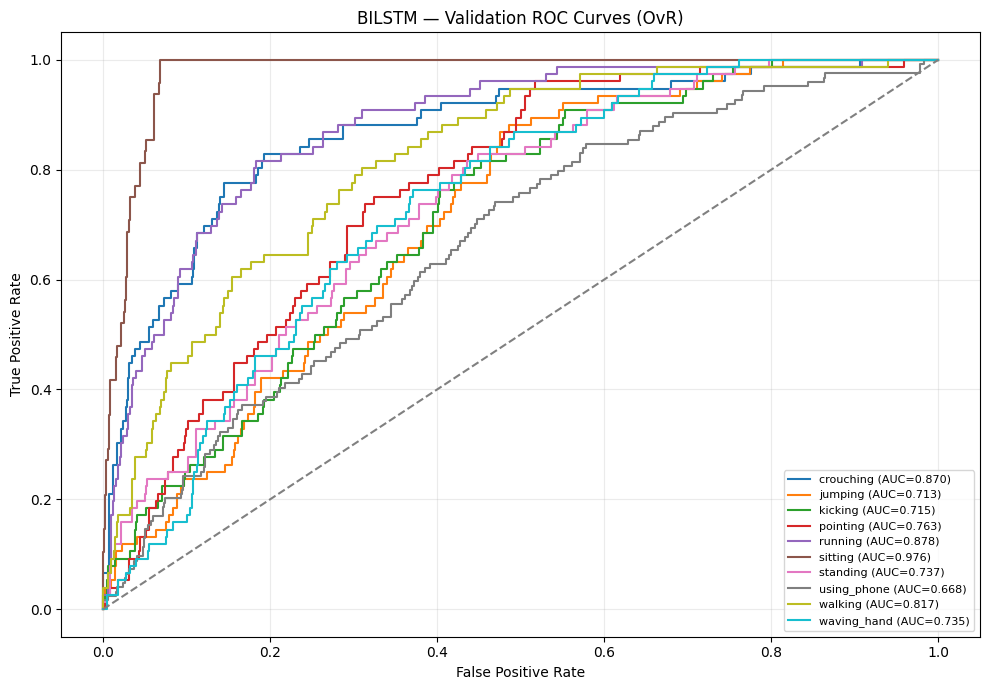

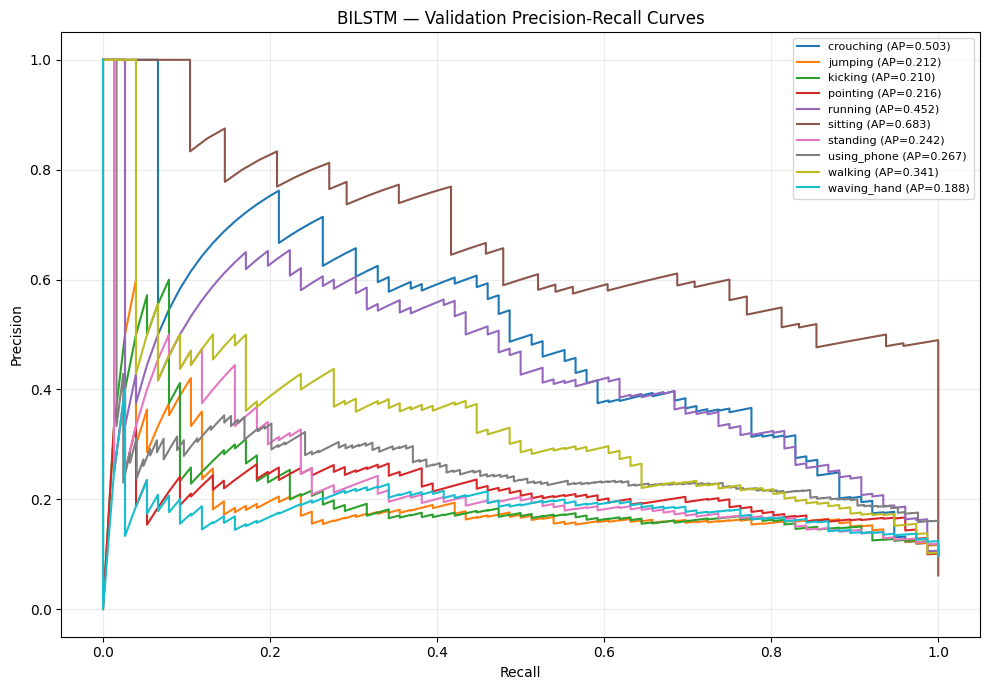


EVALUATING: TCN
{
  "model": "TCN",
  "checkpoint_epoch": 9,
  "validation_samples": 780,
  "validation_macro_roc_auc_ovr": 0.8012021682201483,
  "validation_macro_average_precision": 0.3507642276519906
}


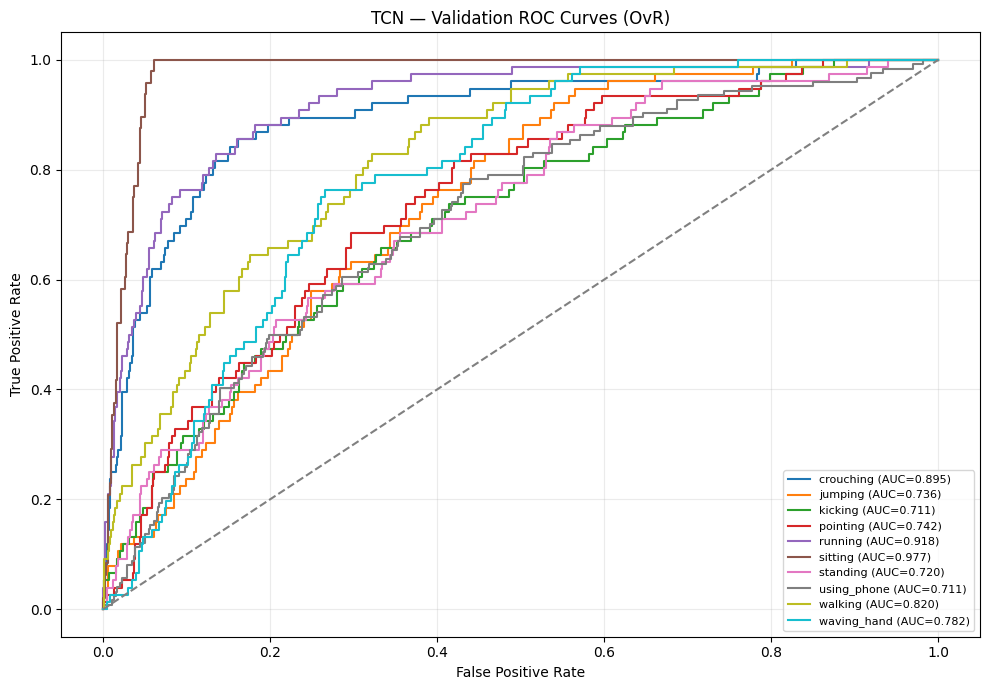

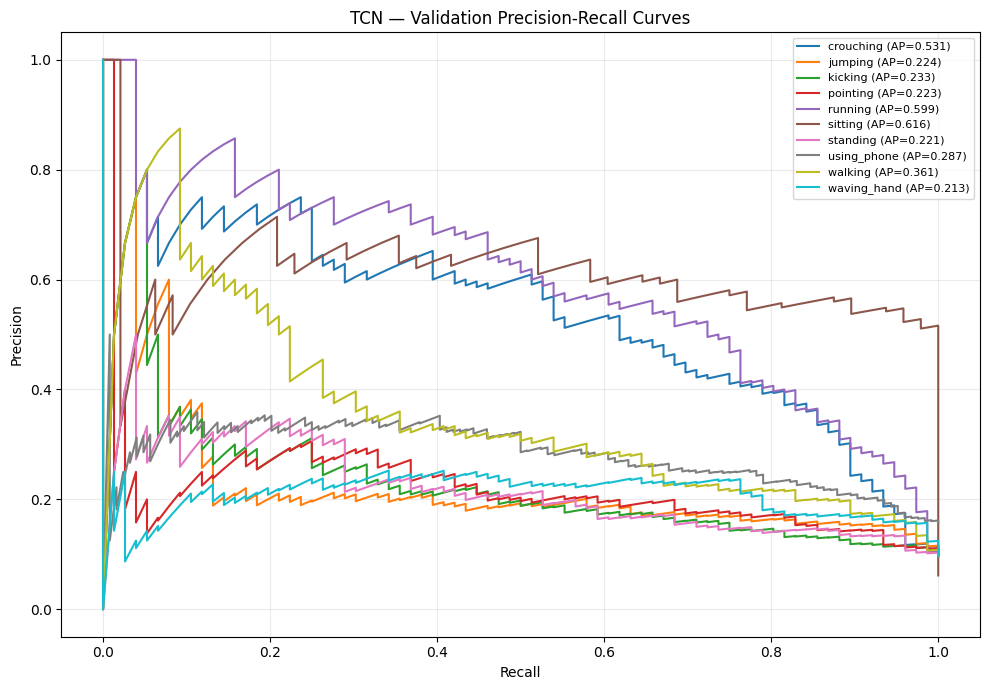

,model,checkpoint_epoch,validation_samples,validation_macro_roc_auc_ovr,validation_macro_average_precision
0,BILSTM,11,780,0.7870,0.3314
1,TCN,9,780,0.8012,0.3508



ROC/PR evaluation completed successfully.
Validation samples: 780
Saved outputs: /kaggle/working/HAR-MMAct/outputs/video_improvement_runs/20261116_091302/temporal_heads/roc_pr_recomputed_float32


In [15]:
# ============================================================
# FINAL ROC-AUC + PRECISION-RECALL EVALUATION
# Exact original BiLSTM and TCN architectures
# Validation set only — no training
# ============================================================

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from pathlib import Path
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve,
    auc
)

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

CLASS_NAMES = list(CLASSES)
NUM_CLASSES = len(CLASS_NAMES)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

OUTPUT_DIR = (
    Path(bilstm_result["checkpoint"]).parent.parent
    / "roc_pr_recomputed_float32"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Device:", DEVICE)
print("Classes:", CLASS_NAMES)
print("Output:", OUTPUT_DIR)

# ------------------------------------------------------------
# 2. Exact original model architecture
# ------------------------------------------------------------

class TCNResidualBlock(nn.Module):
    def __init__(self, channels, dilation, dropout=0.15):
        super().__init__()

        self.network = nn.Sequential(
            nn.Conv1d(
                channels, channels,
                kernel_size=3,
                padding=dilation,
                dilation=dilation
            ),
            nn.GroupNorm(8, channels),
            nn.GELU(),
            nn.Dropout(dropout),

            nn.Conv1d(
                channels, channels,
                kernel_size=3,
                padding=dilation,
                dilation=dilation
            ),
            nn.GroupNorm(8, channels)
        )

        self.activation = nn.GELU()

    def forward(self, x):
        return self.activation(x + self.network(x))


class TemporalClassifier(nn.Module):
    def __init__(self, kind, num_classes=10):
        super().__init__()

        self.kind = kind

        if kind == "bilstm":

            self.project = nn.Sequential(
                nn.Linear(1280, 256),
                nn.LayerNorm(256),
                nn.GELU(),
                nn.Dropout(0.25)
            )

            self.temporal = nn.LSTM(
                input_size=256,
                hidden_size=128,
                num_layers=1,
                batch_first=True,
                bidirectional=True
            )

            out_dim = 256

        elif kind == "tcn":

            self.project = nn.Sequential(
                nn.Linear(1280, 128),
                nn.LayerNorm(128),
                nn.GELU()
            )

            self.temporal = nn.Sequential(
                TCNResidualBlock(128, dilation=1),
                TCNResidualBlock(128, dilation=2),
                TCNResidualBlock(128, dilation=4)
            )

            out_dim = 128

        else:
            raise ValueError("kind must be bilstm or tcn")

        self.classifier = nn.Sequential(
            nn.LayerNorm(out_dim * 2),
            nn.Dropout(0.30),
            nn.Linear(out_dim * 2, 128),
            nn.GELU(),
            nn.Dropout(0.25),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.project(x)

        if self.kind == "bilstm":
            x, _ = self.temporal(x)
        else:
            x = self.temporal(x.transpose(1, 2))
            x = x.transpose(1, 2)

        pooled = torch.cat(
            [x.mean(dim=1), x.max(dim=1).values],
            dim=1
        )

        return self.classifier(pooled)


# ------------------------------------------------------------
# 3. Prepare validation data
# ------------------------------------------------------------

if isinstance(X_val, np.ndarray):
    X_val_tensor = torch.from_numpy(X_val)
else:
    X_val_tensor = X_val.detach().cpu()

if isinstance(y_val, np.ndarray):
    y_val_tensor = torch.from_numpy(y_val)
else:
    y_val_tensor = y_val.detach().cpu()

X_val_tensor = X_val_tensor.float()
y_val_tensor = y_val_tensor.long().reshape(-1)

assert X_val_tensor.shape == (780, 16, 1280)
assert len(y_val_tensor) == 780
assert set(y_val_tensor.numpy()) == set(range(NUM_CLASSES))

val_loader_eval = DataLoader(
    TensorDataset(X_val_tensor, y_val_tensor),
    batch_size=128,
    shuffle=False,
    num_workers=0
)

# ------------------------------------------------------------
# 4. Load exact checkpoints and calculate probabilities
# ------------------------------------------------------------

model_results = {}

for kind, result in [
    ("bilstm", bilstm_result),
    ("tcn", tcn_result)
]:

    print("\n" + "=" * 60)
    print("EVALUATING:", kind.upper())
    print("=" * 60)

    checkpoint_path = Path(result["checkpoint"])
    assert checkpoint_path.exists(), (
        f"Missing checkpoint: {checkpoint_path}"
    )

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False
    )

    model = TemporalClassifier(
        kind=kind,
        num_classes=NUM_CLASSES
    )

    incompatible = model.load_state_dict(
        checkpoint["model_state_dict"],
        strict=True
    )

    assert not incompatible.missing_keys
    assert not incompatible.unexpected_keys

    model = model.to(DEVICE)
    model.eval()

    all_probabilities = []
    all_labels = []

    with torch.inference_mode():

        for xb, yb in val_loader_eval:

            xb = xb.to(
                DEVICE,
                dtype=torch.float32
            )

            # FP32 logits and FP32 softmax
            logits = model(xb)
            probabilities = torch.softmax(
                logits.float(),
                dim=1
            )

            all_probabilities.append(
                probabilities.cpu().numpy()
            )

            all_labels.append(yb.numpy())

    probabilities = np.concatenate(
        all_probabilities,
        axis=0
    )

    y_true = np.concatenate(
        all_labels,
        axis=0
    )

    # Probability integrity checks
    assert probabilities.shape == (780, NUM_CLASSES)
    assert np.all(np.isfinite(probabilities))
    assert np.all(probabilities >= 0)
    assert np.allclose(
        probabilities.sum(axis=1),
        1.0,
        atol=1e-6
    )

    # Multiclass targets
    y_true_onehot = np.eye(NUM_CLASSES)[y_true]

    # Macro ROC-AUC, One-vs-Rest
    macro_roc_auc = roc_auc_score(
        y_true,
        probabilities,
        multi_class="ovr",
        average="macro",
        labels=np.arange(NUM_CLASSES)
    )

    # Macro Average Precision
    macro_ap = average_precision_score(
        y_true_onehot,
        probabilities,
        average="macro"
    )

    model_metrics = {
        "model": kind.upper(),
        "checkpoint_epoch": int(checkpoint["epoch"]),
        "validation_samples": len(y_true),
        "validation_macro_roc_auc_ovr": float(macro_roc_auc),
        "validation_macro_average_precision": float(macro_ap)
    }

    model_results[kind] = {
        "metrics": model_metrics,
        "probabilities": probabilities,
        "y_true": y_true
    }

    print(json.dumps(model_metrics, indent=2))

    # --------------------------------------------------------
    # 5. One-vs-Rest ROC curves
    # --------------------------------------------------------

    plt.figure(figsize=(10, 7))

    for i, class_name in enumerate(CLASS_NAMES):

        fpr, tpr, _ = roc_curve(
            y_true_onehot[:, i],
            probabilities[:, i]
        )

        class_auc = auc(fpr, tpr)

        plt.plot(
            fpr,
            tpr,
            label=f"{class_name} (AUC={class_auc:.3f})"
        )

    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        color="gray"
    )

    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(
        f"{kind.upper()} — Validation ROC Curves (OvR)"
    )
    plt.legend(fontsize=8, loc="lower right")
    plt.grid(alpha=0.25)
    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR / f"{kind}_validation_roc.png",
        dpi=180
    )
    plt.show()
    plt.close()

    # --------------------------------------------------------
    # 6. One-vs-Rest Precision-Recall curves
    # --------------------------------------------------------

    plt.figure(figsize=(10, 7))

    for i, class_name in enumerate(CLASS_NAMES):

        precision, recall, _ = precision_recall_curve(
            y_true_onehot[:, i],
            probabilities[:, i]
        )

        class_ap = average_precision_score(
            y_true_onehot[:, i],
            probabilities[:, i]
        )

        plt.plot(
            recall,
            precision,
            label=f"{class_name} (AP={class_ap:.3f})"
        )

    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title(
        f"{kind.upper()} — Validation Precision-Recall Curves"
    )
    plt.legend(fontsize=8, loc="best")
    plt.grid(alpha=0.25)
    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR / f"{kind}_validation_pr.png",
        dpi=180
    )
    plt.show()
    plt.close()

    # Save reproducible predictions
    prediction_df = pd.DataFrame(
        probabilities,
        columns=[f"prob_{name}" for name in CLASS_NAMES]
    )

    prediction_df.insert(
        0,
        "ground_truth",
        [CLASS_NAMES[i] for i in y_true]
    )

    prediction_df.to_csv(
        OUTPUT_DIR / f"{kind}_validation_probabilities.csv",
        index=False
    )


# ------------------------------------------------------------
# 7. Final ROC-AUC and PR comparison
# ------------------------------------------------------------

comparison_df = pd.DataFrame([
    model_results["bilstm"]["metrics"],
    model_results["tcn"]["metrics"]
])

comparison_df.to_csv(
    OUTPUT_DIR / "temporal_roc_pr_comparison.csv",
    index=False
)

with open(
    OUTPUT_DIR / "temporal_roc_pr_comparison.json",
    "w"
) as f:
    json.dump(
        comparison_df.to_dict(orient="records"),
        f,
        indent=2
    )

display(
    comparison_df.style.format({
        "validation_macro_roc_auc_ovr": "{:.4f}",
        "validation_macro_average_precision": "{:.4f}"
    })
)

print("\nROC/PR evaluation completed successfully.")
print("Validation samples:", len(y_true))
print("Saved outputs:", OUTPUT_DIR)

**Compare all new models using validation results**

,Model,Validation Accuracy,Macro F1
0,Original MobileNetV2,35.260000,0.349200
1,Previous Staged MobileNetV2,36.540000,NaN
2,MobileNetV2 Fine-tuning V2,30.128205,0.293236
3,MobileNetV2 + BiLSTM,31.410256,0.321584
4,MobileNetV2 + TCN,34.743590,0.343225


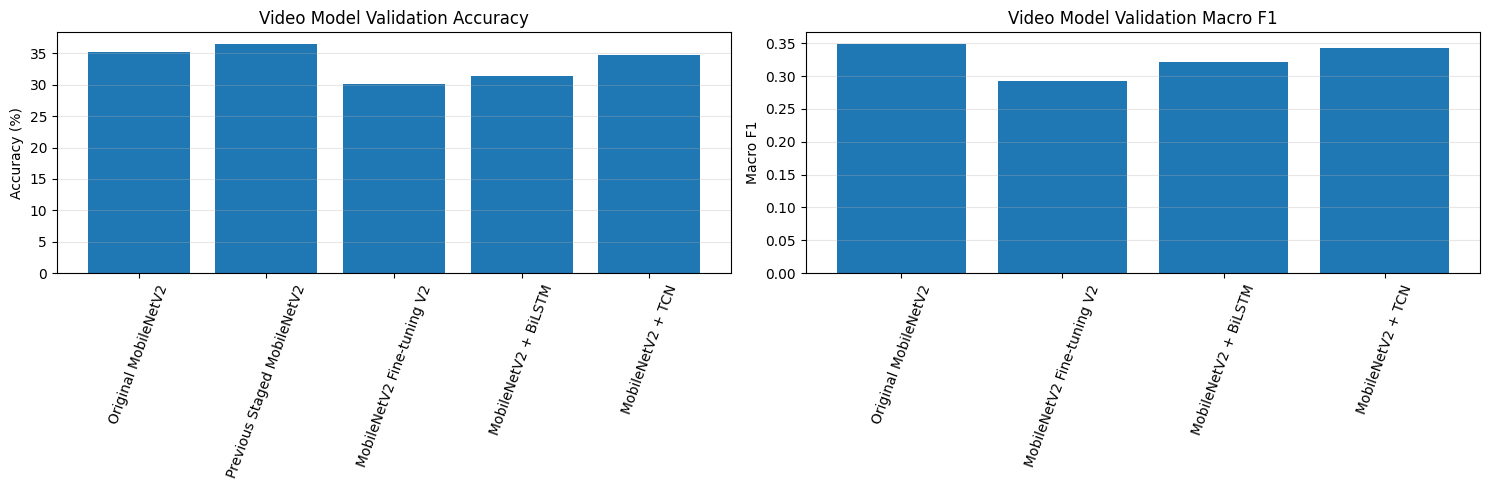

Selected validation candidate: MobileNetV2 + TCN
Validation Macro F1: 0.34322513923450615


In [16]:

import json
import pandas as pd
import matplotlib.pyplot as plt

with open(
    FINAL_MOBILENET_DIR / "training_summary_mobilenet_v2.json"
) as f:
    finetune_summary = json.load(f)

finetune_metrics = finetune_summary["best_metrics"]

comparison_rows = [
    {
        "Model": "Original MobileNetV2",
        "Validation Accuracy": 35.26,
        "Macro F1": 0.3492
    },
    {
        "Model": "Previous Staged MobileNetV2",
        "Validation Accuracy": 36.54,
        "Macro F1": np.nan
    },
    {
        "Model": "MobileNetV2 Fine-tuning V2",
        "Validation Accuracy": finetune_metrics["accuracy"] * 100,
        "Macro F1": finetune_metrics["macro_f1"]
    },
    {
        "Model": "MobileNetV2 + BiLSTM",
        "Validation Accuracy": bilstm_result["metrics"]["accuracy"] * 100,
        "Macro F1": bilstm_result["metrics"]["macro_f1"]
    },
    {
        "Model": "MobileNetV2 + TCN",
        "Validation Accuracy": tcn_result["metrics"]["accuracy"] * 100,
        "Macro F1": tcn_result["metrics"]["macro_f1"]
    }
]

comparison_df = pd.DataFrame(comparison_rows)

COMPARISON_DIR = OUTPUT_ROOT / "video_model_comparison"
COMPARISON_DIR.mkdir(parents=True, exist_ok=True)

display(comparison_df)

comparison_df.to_csv(
    COMPARISON_DIR / "validation_comparison.csv",
    index=False
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].bar(
    comparison_df["Model"],
    comparison_df["Validation Accuracy"]
)
axes[0].set_title("Video Model Validation Accuracy")
axes[0].set_ylabel("Accuracy (%)")
axes[0].tick_params(axis="x", rotation=70)
axes[0].grid(axis="y", alpha=0.3)

valid_f1 = comparison_df.dropna(subset=["Macro F1"])

axes[1].bar(
    valid_f1["Model"],
    valid_f1["Macro F1"]
)
axes[1].set_title("Video Model Validation Macro F1")
axes[1].set_ylabel("Macro F1")
axes[1].tick_params(axis="x", rotation=70)
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(
    COMPARISON_DIR / "video_validation_comparison.png",
    dpi=200
)
plt.show()

# Choose the new candidate strictly using validation Macro F1.
new_candidates = {
    "MobileNetV2 Fine-tuning V2": finetune_metrics["macro_f1"],
    "MobileNetV2 + BiLSTM": bilstm_result["metrics"]["macro_f1"],
    "MobileNetV2 + TCN": tcn_result["metrics"]["macro_f1"]
}

WINNER_NAME = max(
    new_candidates,
    key=new_candidates.get
)

print("Selected validation candidate:", WINNER_NAME)
print("Validation Macro F1:", new_candidates[WINNER_NAME])

with open(COMPARISON_DIR / "validation_model_selection.json", "w") as f:
    json.dump(
        {
            "selection_metric": "Validation Macro F1",
            "selected_model": WINNER_NAME,
            "candidate_scores": new_candidates,
            "test_evaluation_performed": False
        },
        f,
        indent=2
    )


**Final TCN test evaluation**

Selected candidate: MobileNetV2 + TCN
Checkpoint: /kaggle/working/HAR-MMAct/outputs/video_improvement_runs/20261116_091302/temporal_heads/tcn/best_model.pth
Test samples: 852
Test feature shape: (852, 16, 1280)
Unique test IDs: 852
All 10 classes represented.
TCN checkpoint loaded successfully.
Selected epoch: 9
Validation Macro F1: 0.34322513923450615

FINAL TCN TEST METRICS
{
  "model": "MobileNetV2 + TCN",
  "checkpoint_epoch": 9,
  "test_samples": 852,
  "test_loss": 2.1416195793330948,
  "accuracy": 0.33568075117370894,
  "macro_precision": 0.32769084074029264,
  "macro_recall": 0.3716179653679654,
  "macro_f1": 0.32771432655738636,
  "roc_auc_ovr_macro": 0.8053045669414024,
  "macro_average_precision": 0.3699222749161116
}


,precision,recall,f1-score,support
crouching,0.480315,0.726190,0.578199,84.000000
jumping,0.181818,0.190476,0.186047,84.000000
kicking,0.309524,0.154762,0.206349,84.000000
pointing,0.225000,0.321429,0.264706,84.000000
running,0.522124,0.702381,0.598985,84.000000
sitting,0.494737,0.979167,0.657343,48.000000
standing,0.195652,0.107143,0.138462,84.000000
using_phone,0.204918,0.189394,0.196850,132.000000
walking,0.512821,0.238095,0.325203,84.000000
waving_hand,0.150000,0.107143,0.125000,84.000000


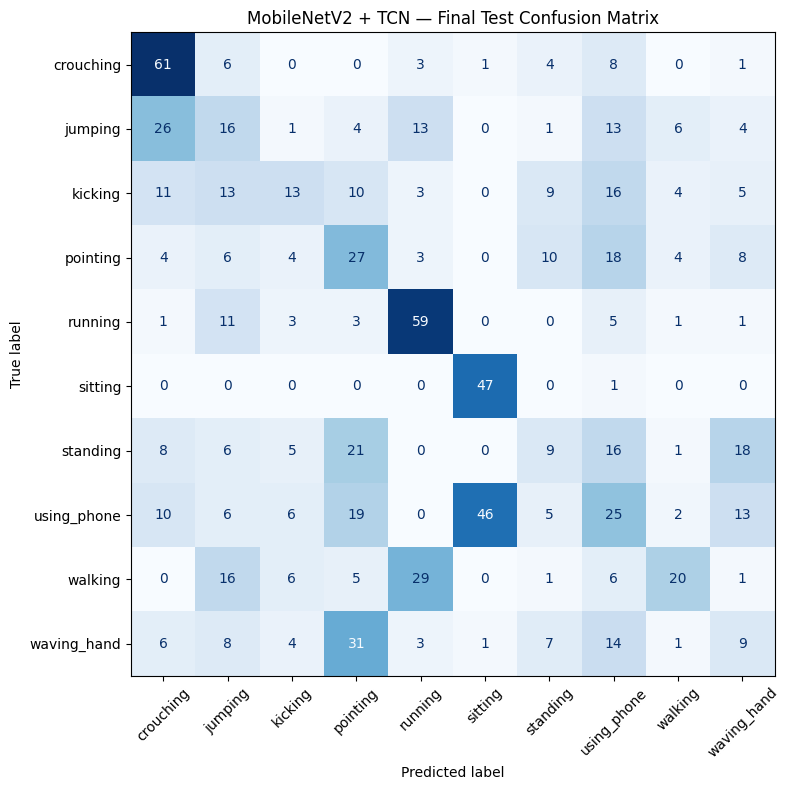

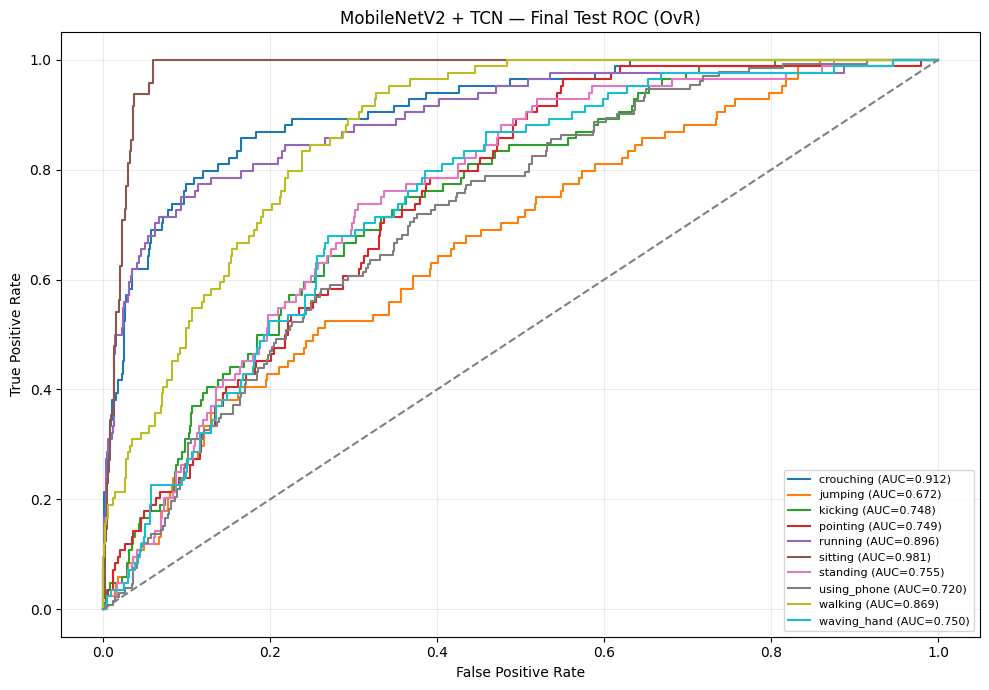

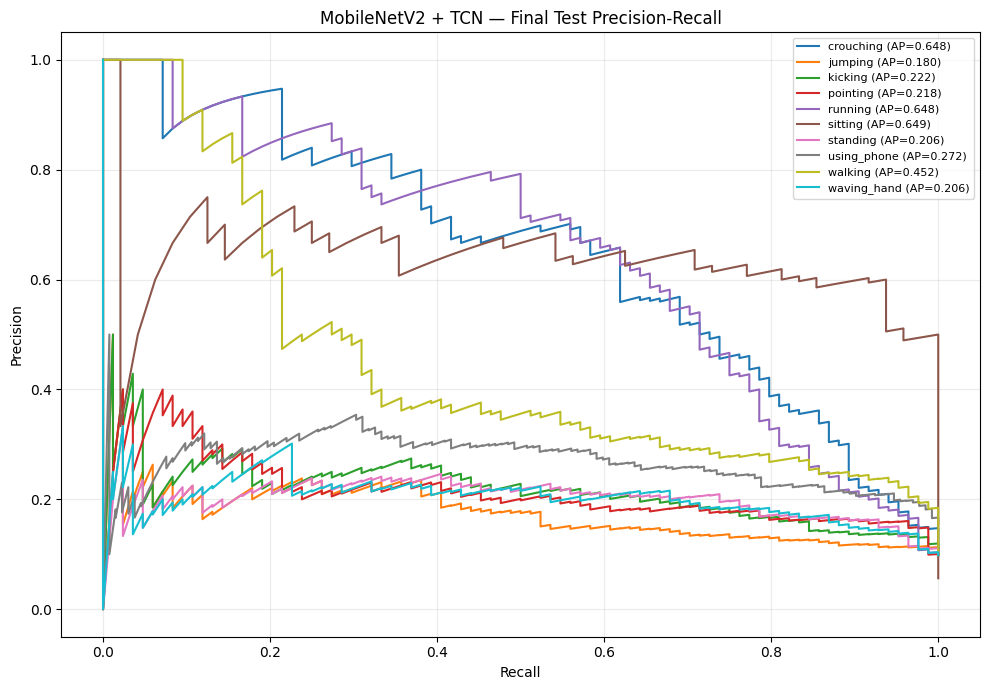


FINAL TEST EVALUATION COMPLETED.
Test samples evaluated: 852
Saved outputs: /kaggle/working/HAR-MMAct/outputs/video_model_comparison/final_selected_test/mobilenetv2_tcn


In [17]:
# ============================================================
# CELL 8: FINAL TEST EVALUATION — MobileNetV2 + TCN
# Uses the selected validation checkpoint.
# Do not use this test result for further model selection.
# ============================================================

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from pathlib import Path
from torch.utils.data import DataLoader
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve,
    auc
)

from src.data.dataset import MMActMultimodalDataset

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

CLASS_NAMES = list(VERIFIED_TARGET_CLASSES)
NUM_CLASSES = len(CLASS_NAMES)

TEST_DIR = (
    COMPARISON_DIR / "final_selected_test" / "mobilenetv2_tcn"
)
TEST_DIR.mkdir(parents=True, exist_ok=True)

TCN_CHECKPOINT = Path(tcn_result["checkpoint"])

assert TCN_CHECKPOINT.exists(), "TCN checkpoint missing."
assert len(test_samples) == 852, (
    f"Expected 852 test samples, found {len(test_samples)}"
)

print("Selected candidate: MobileNetV2 + TCN")
print("Checkpoint:", TCN_CHECKPOINT)
print("Test samples:", len(test_samples))

# ------------------------------------------------------------
# 2. Extract test features from the same fine-tuned backbone
# ------------------------------------------------------------

assert feature_model is not None
feature_model = feature_model.to(DEVICE).eval()
video_branch = feature_model.video_branch

test_dataset = MMActMultimodalDataset(
    test_samples,
    cache_dir=CACHE_DIR / "test",
    enable_cache=True,
    mode="video_only"
)

test_loader = DataLoader(
    test_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_features = []
test_labels = []
test_ids = []

with torch.inference_mode():
    for videos, sensors, labels, sample_ids in test_loader:

        videos = videos.to(DEVICE, non_blocking=True)

        b, c, t, h, w = videos.shape

        frames = (
            videos.permute(0, 2, 1, 3, 4)
            .reshape(b * t, c, h, w)
        )

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=(DEVICE.type == "cuda")
        ):
            frame_maps = video_branch.backbone(frames)

            frame_features = (
                video_branch.backbone_pool(frame_maps)
                .flatten(1)
            )

        sequence = frame_features.reshape(
            b, t, 1280
        ).cpu().float()

        test_features.append(sequence)
        test_labels.append(labels.cpu().long())
        test_ids.extend(list(sample_ids))

X_test = torch.cat(test_features, dim=0)
y_test = torch.cat(test_labels, dim=0).numpy()

assert X_test.shape == (852, 16, 1280)
assert len(y_test) == 852
assert len(test_ids) == 852
assert len(set(test_ids)) == 852
assert set(np.unique(y_test)) == set(range(NUM_CLASSES))

print("Test feature shape:", tuple(X_test.shape))
print("Unique test IDs:", len(set(test_ids)))
print("All 10 classes represented.")

# ------------------------------------------------------------
# 3. Reconstruct the exact original TCN architecture
# ------------------------------------------------------------

class TCNResidualBlock(nn.Module):
    def __init__(self, channels, dilation, dropout=0.15):
        super().__init__()

        self.network = nn.Sequential(
            nn.Conv1d(
                channels, channels,
                kernel_size=3,
                padding=dilation,
                dilation=dilation
            ),
            nn.GroupNorm(8, channels),
            nn.GELU(),
            nn.Dropout(dropout),

            nn.Conv1d(
                channels, channels,
                kernel_size=3,
                padding=dilation,
                dilation=dilation
            ),
            nn.GroupNorm(8, channels)
        )

        self.activation = nn.GELU()

    def forward(self, x):
        return self.activation(x + self.network(x))


class TemporalClassifier(nn.Module):
    def __init__(self, kind, num_classes=10):
        super().__init__()

        self.kind = kind

        if kind != "tcn":
            raise ValueError("This cell evaluates the TCN only.")

        self.project = nn.Sequential(
            nn.Linear(1280, 128),
            nn.LayerNorm(128),
            nn.GELU()
        )

        self.temporal = nn.Sequential(
            TCNResidualBlock(128, dilation=1),
            TCNResidualBlock(128, dilation=2),
            TCNResidualBlock(128, dilation=4)
        )

        out_dim = 128

        self.classifier = nn.Sequential(
            nn.LayerNorm(out_dim * 2),
            nn.Dropout(0.30),
            nn.Linear(out_dim * 2, 128),
            nn.GELU(),
            nn.Dropout(0.25),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.project(x)
        x = self.temporal(x.transpose(1, 2))
        x = x.transpose(1, 2)

        pooled = torch.cat(
            [x.mean(dim=1), x.max(dim=1).values],
            dim=1
        )

        return self.classifier(pooled)


checkpoint = torch.load(
    TCN_CHECKPOINT,
    map_location="cpu",
    weights_only=False
)

assert checkpoint["kind"] == "tcn"

model = TemporalClassifier("tcn", NUM_CLASSES)

model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

model = model.to(DEVICE).eval()

print("TCN checkpoint loaded successfully.")
print("Selected epoch:", checkpoint["epoch"])
print("Validation Macro F1:", checkpoint["best_val_macro_f1"])

# ------------------------------------------------------------
# 4. Predict on the held-out test set
# ------------------------------------------------------------

all_logits = []
all_probabilities = []

test_eval_loader = DataLoader(
    torch.utils.data.TensorDataset(
        X_test,
        torch.from_numpy(y_test).long()
    ),
    batch_size=128,
    shuffle=False
)

test_loss_sum = 0.0
test_targets = []

with torch.inference_mode():
    for xb, yb in test_eval_loader:

        xb = xb.to(DEVICE, dtype=torch.float32)
        yb_device = yb.to(DEVICE)

        logits = model(xb)
        probabilities = torch.softmax(
            logits.float(), dim=1
        )

        loss = nn.functional.cross_entropy(
            logits.float(),
            yb_device,
            reduction="sum"
        )

        test_loss_sum += loss.item()

        all_logits.append(logits.float().cpu().numpy())
        all_probabilities.append(probabilities.cpu().numpy())
        test_targets.extend(yb.numpy())

y_true = np.asarray(test_targets, dtype=np.int64)
y_score = np.concatenate(all_probabilities, axis=0)
y_pred = y_score.argmax(axis=1)

assert y_score.shape == (852, NUM_CLASSES)
assert np.all(np.isfinite(y_score))
assert np.allclose(y_score.sum(axis=1), 1.0, atol=1e-5)

# ------------------------------------------------------------
# 5. Calculate final test metrics
# ------------------------------------------------------------

y_true_onehot = np.eye(NUM_CLASSES)[y_true]

metrics = {
    "model": "MobileNetV2 + TCN",
    "checkpoint_epoch": int(checkpoint["epoch"]),
    "test_samples": len(y_true),
    "test_loss": float(test_loss_sum / len(y_true)),
    "accuracy": float(accuracy_score(y_true, y_pred)),
    "macro_precision": float(
        precision_score(y_true, y_pred, average="macro", zero_division=0)
    ),
    "macro_recall": float(
        recall_score(y_true, y_pred, average="macro", zero_division=0)
    ),
    "macro_f1": float(
        f1_score(y_true, y_pred, average="macro", zero_division=0)
    ),
    "roc_auc_ovr_macro": float(
        roc_auc_score(
            y_true,
            y_score,
            multi_class="ovr",
            average="macro"
        )
    ),
    "macro_average_precision": float(
        average_precision_score(
            y_true_onehot,
            y_score,
            average="macro"
        )
    )
}

print("\nFINAL TCN TEST METRICS")
print(json.dumps(metrics, indent=2))

# ------------------------------------------------------------
# 6. Per-class evaluation
# ------------------------------------------------------------

report = classification_report(
    y_true,
    y_pred,
    labels=np.arange(NUM_CLASSES),
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0
)

per_class_df = pd.DataFrame(report).transpose()

per_class_df.to_csv(
    TEST_DIR / "per_class_test_metrics.csv"
)

display(per_class_df)

# ------------------------------------------------------------
# 7. Save predictions and metrics
# ------------------------------------------------------------

prediction_df = pd.DataFrame({
    "sample_id": test_ids,
    "ground_truth": [CLASS_NAMES[i] for i in y_true],
    "prediction": [CLASS_NAMES[i] for i in y_pred],
    "confidence": y_score.max(axis=1)
})

for i, class_name in enumerate(CLASS_NAMES):
    prediction_df[f"prob_{class_name}"] = y_score[:, i]

prediction_df.to_csv(
    TEST_DIR / "test_predictions.csv",
    index=False
)

with open(TEST_DIR / "test_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

# ------------------------------------------------------------
# 8. Confusion matrix
# ------------------------------------------------------------

cm = confusion_matrix(
    y_true, y_pred,
    labels=np.arange(NUM_CLASSES)
)

fig, ax = plt.subplots(figsize=(10, 8))

disp = __import__(
    "sklearn.metrics", fromlist=["ConfusionMatrixDisplay"]
).ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES
)

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    colorbar=False
)

ax.set_title("MobileNetV2 + TCN — Final Test Confusion Matrix")
plt.tight_layout()
plt.savefig(TEST_DIR / "test_confusion_matrix.png", dpi=180)
plt.show()
plt.close()

# ------------------------------------------------------------
# 9. Multiclass ROC curves
# ------------------------------------------------------------

plt.figure(figsize=(10, 7))

for i, class_name in enumerate(CLASS_NAMES):
    fpr, tpr, _ = roc_curve(
        y_true_onehot[:, i],
        y_score[:, i]
    )

    class_auc = auc(fpr, tpr)

    plt.plot(
        fpr, tpr,
        label=f"{class_name} (AUC={class_auc:.3f})"
    )

plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("MobileNetV2 + TCN — Final Test ROC (OvR)")
plt.legend(fontsize=8, loc="lower right")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(TEST_DIR / "test_roc_curves.png", dpi=180)
plt.show()
plt.close()

# ------------------------------------------------------------
# 10. Multiclass Precision-Recall curves
# ------------------------------------------------------------

plt.figure(figsize=(10, 7))

for i, class_name in enumerate(CLASS_NAMES):
    precision, recall, _ = precision_recall_curve(
        y_true_onehot[:, i],
        y_score[:, i]
    )

    class_ap = average_precision_score(
        y_true_onehot[:, i],
        y_score[:, i]
    )

    plt.plot(
        recall, precision,
        label=f"{class_name} (AP={class_ap:.3f})"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("MobileNetV2 + TCN — Final Test Precision-Recall")
plt.legend(fontsize=8)
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(TEST_DIR / "test_pr_curves.png", dpi=180)
plt.show()
plt.close()

print("\nFINAL TEST EVALUATION COMPLETED.")
print("Test samples evaluated:", len(y_true))
print("Saved outputs:", TEST_DIR)

**Build the complete 10-model benchmark**

,test_rank_by_macro_f1,model,modality,accuracy,precision,recall,macro_f1,roc_auc_ovr,macro_ap,test_samples
0,1,Primary Multimodal MobileNetV2 + InceptionTime,Multimodal,76.76%,0.7843,0.7652,0.7545,0.9661,0.8590,852
1,2,Additional Multimodal Fusion,Multimodal,75.47%,0.7770,0.7538,0.7464,0.9662,0.8500,852
2,3,Gated Multimodal TCN,Multimodal,73.94%,0.7699,0.7392,0.7241,0.9582,0.8268,852
3,4,Sensor-only TCN,Sensor-only,74.65%,0.8133,0.7429,0.7190,0.9524,0.8094,852
4,5,Sensor-only InceptionTime,Sensor-only,68.54%,0.7070,0.6810,0.6563,0.9311,0.7742,852
5,6,Retrained MobileNetV2,Video-only,42.49%,0.4665,0.4552,0.4317,0.8443,0.4732,852
6,7,Original MobileNetV2,Video-only,42.14%,0.4473,0.4590,0.4153,0.8609,0.4982,852
7,8,MobileNetV2 + TCN,Video-only temporal,33.57%,0.3277,0.3716,0.3277,0.8053,0.3699,852
8,9,Original Custom CNN,Video-only,15.38%,0.1541,0.1727,0.1139,0.6160,0.1791,852
9,10,Retrained Custom CNN V2,Video-only,13.26%,0.1307,0.1449,0.0940,0.6091,0.1786,852


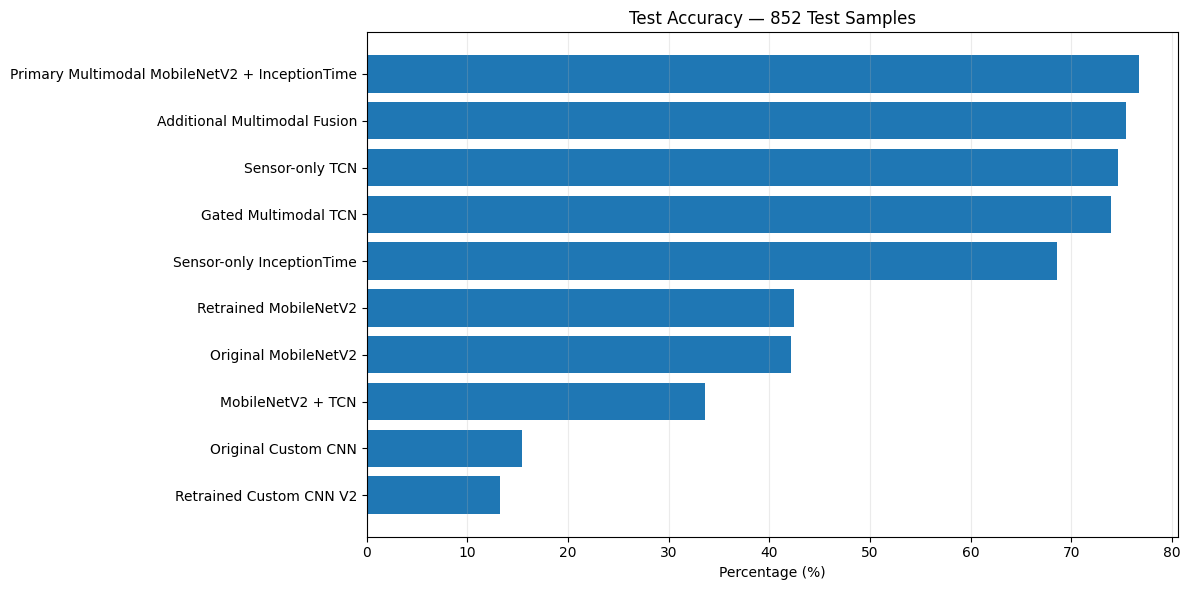

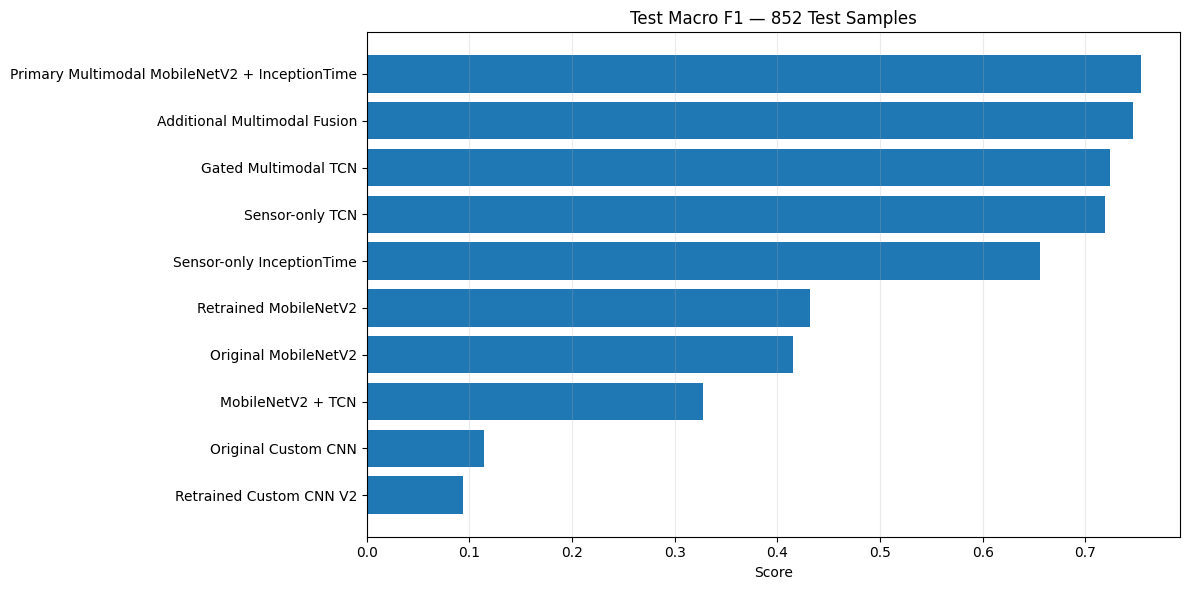

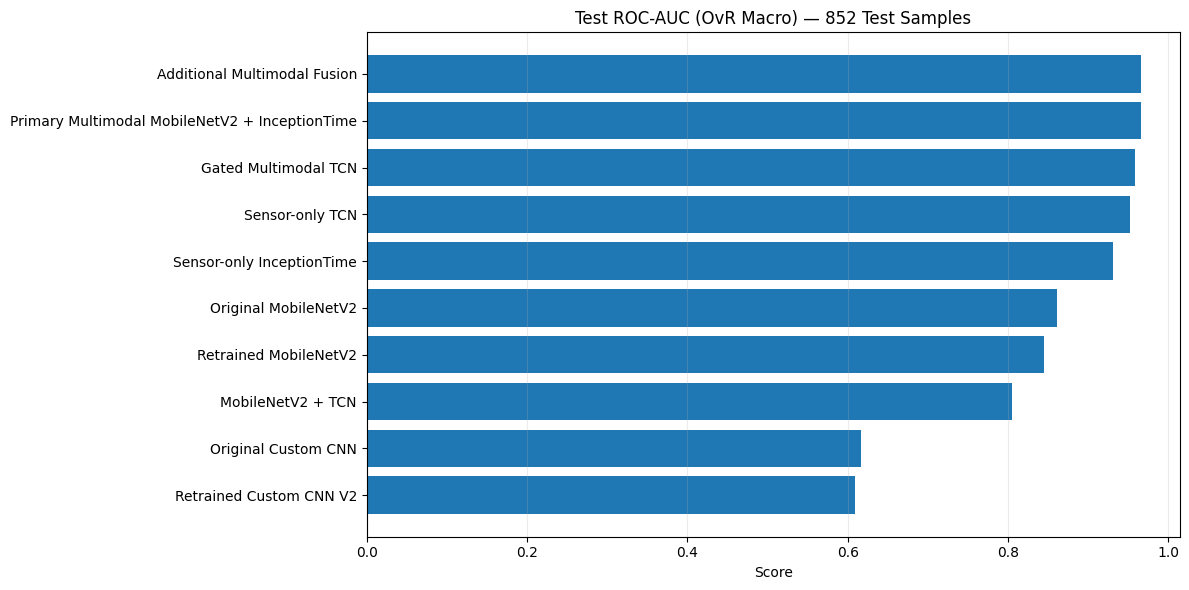

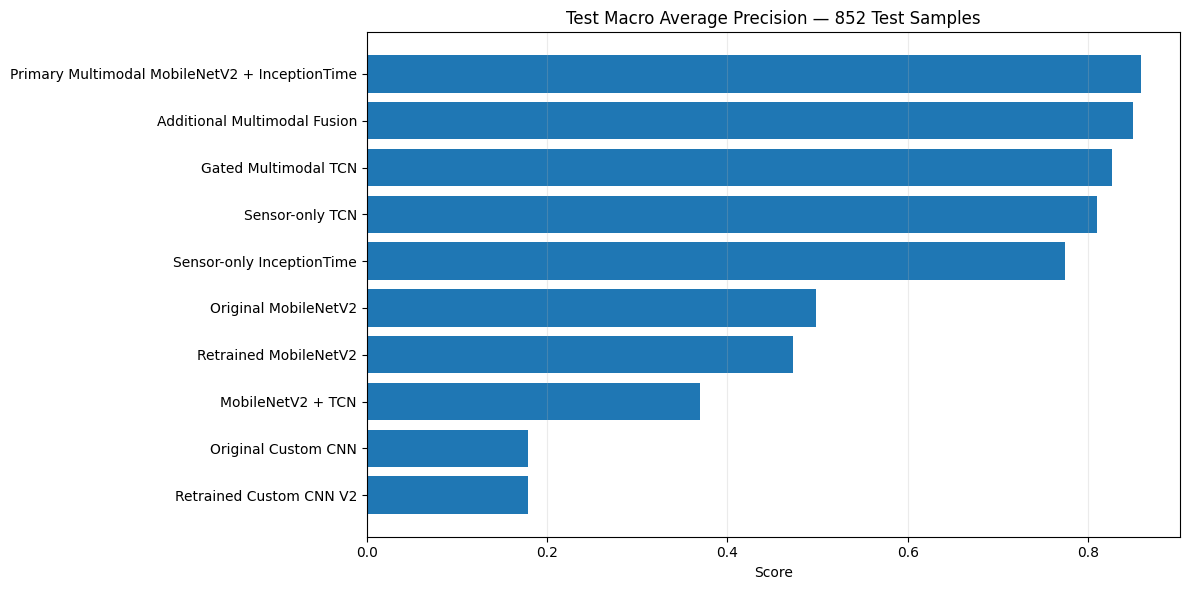


TEN-MODEL COMPARISON COMPLETED
Models: 10
Test samples per model: [np.int64(852)]
Saved to: /kaggle/working/HAR-MMAct/outputs/final_test/all_models_rebuilt/ten_model_final_comparison

Top model by test Macro F1:
{'model': 'Primary Multimodal MobileNetV2 + InceptionTime', 'accuracy': 0.767606, 'macro_f1': 0.7544618}


In [18]:
# ============================================================
# STEP 9: CONSOLIDATE ALL 10 MODEL TEST RESULTS
# ============================================================

import json
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path("/kaggle/working/HAR-MMAct")

TCN_METRICS_FILE = (
    ROOT / "outputs/video_model_comparison/"
    "final_selected_test/mobilenetv2_tcn/test_metrics.json"
)

OUTPUT_DIR = (
    ROOT / "outputs/final_test/all_models_rebuilt/"
    "ten_model_final_comparison"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

assert TCN_METRICS_FILE.exists(), "New TCN test metrics file missing."

with open(TCN_METRICS_FILE) as f:
    tcn = json.load(f)

assert tcn["test_samples"] == 852

# Previously verified nine-model benchmark
rows = [
    {
        "model": "Primary Multimodal MobileNetV2 + InceptionTime",
        "modality": "Multimodal",
        "accuracy": 0.767606,
        "precision": 0.7843291,
        "recall": 0.7651515,
        "macro_f1": 0.7544618,
        "roc_auc_ovr": 0.9661350,
        "macro_ap": 0.8589989
    },
    {
        "model": "Additional Multimodal Fusion",
        "modality": "Multimodal",
        "accuracy": 0.754695,
        "precision": 0.7770245,
        "recall": 0.7537879,
        "macro_f1": 0.7464000,
        "roc_auc_ovr": 0.9662302,
        "macro_ap": 0.8499825
    },
    {
        "model": "Gated Multimodal TCN",
        "modality": "Multimodal",
        "accuracy": 0.739437,
        "precision": 0.7698761,
        "recall": 0.7391775,
        "macro_f1": 0.7241405,
        "roc_auc_ovr": 0.9582143,
        "macro_ap": 0.8267652
    },
    {
        "model": "Sensor-only TCN",
        "modality": "Sensor-only",
        "accuracy": 0.746479,
        "precision": 0.8133463,
        "recall": 0.7428571,
        "macro_f1": 0.7190475,
        "roc_auc_ovr": 0.9523810,
        "macro_ap": 0.8093668
    },
    {
        "model": "Sensor-only InceptionTime",
        "modality": "Sensor-only",
        "accuracy": 0.685446,
        "precision": 0.7069566,
        "recall": 0.6809524,
        "macro_f1": 0.6562830,
        "roc_auc_ovr": 0.9311055,
        "macro_ap": 0.7741910
    },
    {
        "model": "Retrained MobileNetV2",
        "modality": "Video-only",
        "accuracy": 0.424883,
        "precision": 0.4665496,
        "recall": 0.4551677,
        "macro_f1": 0.4316926,
        "roc_auc_ovr": 0.8442961,
        "macro_ap": 0.4731530
    },
    {
        "model": "Original MobileNetV2",
        "modality": "Video-only",
        "accuracy": 0.421362,
        "precision": 0.4473264,
        "recall": 0.4589827,
        "macro_f1": 0.4153285,
        "roc_auc_ovr": 0.8608784,
        "macro_ap": 0.4982421
    },
    {
        "model": "Original Custom CNN",
        "modality": "Video-only",
        "accuracy": 0.153756,
        "precision": 0.1540507,
        "recall": 0.1726732,
        "macro_f1": 0.1139180,
        "roc_auc_ovr": 0.6160074,
        "macro_ap": 0.1791272
    },
    {
        "model": "Retrained Custom CNN V2",
        "modality": "Video-only",
        "accuracy": 0.132629,
        "precision": 0.1307080,
        "recall": 0.1449134,
        "macro_f1": 0.0939734,
        "roc_auc_ovr": 0.6090665,
        "macro_ap": 0.1785642
    }
]

# Read the new TCN result directly from its saved JSON.
rows.append({
    "model": "MobileNetV2 + TCN",
    "modality": "Video-only temporal",
    "accuracy": tcn["accuracy"],
    "precision": tcn["macro_precision"],
    "recall": tcn["macro_recall"],
    "macro_f1": tcn["macro_f1"],
    "roc_auc_ovr": tcn["roc_auc_ovr_macro"],
    "macro_ap": tcn["macro_average_precision"]
})

df = pd.DataFrame(rows)

df = df.sort_values(
    "macro_f1",
    ascending=False
).reset_index(drop=True)

df.insert(0, "test_rank_by_macro_f1", range(1, len(df) + 1))
df["test_samples"] = 852

# Save comparison files
df.to_csv(OUTPUT_DIR / "ten_model_test_comparison.csv", index=False)

with open(OUTPUT_DIR / "ten_model_test_comparison.json", "w") as f:
    json.dump(df.to_dict(orient="records"), f, indent=2)

# Display formatted results
display(
    df.style.format({
        "accuracy": "{:.2%}",
        "precision": "{:.4f}",
        "recall": "{:.4f}",
        "macro_f1": "{:.4f}",
        "roc_auc_ovr": "{:.4f}",
        "macro_ap": "{:.4f}"
    })
)

# Generate four comparison charts
chart_configs = [
    ("accuracy", "Test Accuracy", "test_accuracy.png", True),
    ("macro_f1", "Test Macro F1", "test_macro_f1.png", False),
    ("roc_auc_ovr", "Test ROC-AUC (OvR Macro)", "test_roc_auc.png", False),
    ("macro_ap", "Test Macro Average Precision", "test_macro_ap.png", False)
]

for column, title, filename, percentage in chart_configs:
    plot_df = df.sort_values(column, ascending=True)

    plt.figure(figsize=(12, 6))
    values = plot_df[column] * (100 if percentage else 1)

    plt.barh(plot_df["model"], values)

    plt.xlabel("Percentage (%)" if percentage else "Score")
    plt.title(title + " — 852 Test Samples")
    plt.grid(axis="x", alpha=0.25)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / filename, dpi=180)
    plt.show()
    plt.close()

# Save experiment notes
notes = """
HAR-MMAct — Ten-Model Test Benchmark

Dataset split:
- Subject-independent custom split
- Test samples: 852
- Test subjects: 18, 19, 20
- Ten target activity classes

Selection:
- Model selection was performed using validation results.
- The new MobileNetV2 + TCN checkpoint was selected from
  the new temporal experiments using validation Macro F1.
- The test set was evaluated after selection.

Important interpretation:
- The existing primary multimodal model remains the project champion.
- MobileNetV2 + TCN is an additional video-only temporal experiment.
- Do not describe it as an improvement over the existing benchmark.
- Historical benchmark metrics are retained from the previously
  completed nine-model evaluation.
"""

(OUTPUT_DIR / "experiment_notes.txt").write_text(notes.strip())

print("\nTEN-MODEL COMPARISON COMPLETED")
print("Models:", len(df))
print("Test samples per model:", sorted(df["test_samples"].unique()))
print("Saved to:", OUTPUT_DIR)

print("\nTop model by test Macro F1:")
print(df.iloc[0][["model", "accuracy", "macro_f1"]].to_dict())

**Package final results**

In [19]:
import shutil
import json
from pathlib import Path
from datetime import datetime

ROOT = Path("/kaggle/working/HAR-MMAct")

PACKAGE_DIR = Path(
    "/kaggle/working/HAR_MMAct_Final_Results"
)

# Recreate only the packaging directory.
if PACKAGE_DIR.exists():
    shutil.rmtree(PACKAGE_DIR)

PACKAGE_DIR.mkdir(parents=True)

sources = {
    "ten_model_benchmark":
        ROOT / "outputs/final_test/all_models_rebuilt",

    "tcn_final_test":
        ROOT / "outputs/video_model_comparison/final_selected_test/mobilenetv2_tcn",

    "mobilenetv2_finetuning_v2":
        ROOT / "outputs/video_mobilenet_v2_finetune_v2",

    "temporal_heads":
        ROOT / "outputs/video_improvement_runs/20261116_091302/temporal_heads",

    "hyperparameter_search":
        ROOT / "outputs/video_improvement_runs/20261116_091302/mobilenet_hparam_search",

    "video_validation_comparison":
        ROOT / "outputs/video_improvement_runs/20261116_091302/final_comparison"
}

manifest = []

for name, source in sources.items():
    if not source.exists():
        print("WARNING - Missing:", source)
        continue

    destination = PACKAGE_DIR / name

    shutil.copytree(
        source,
        destination,
        dirs_exist_ok=True
    )

    files = list(destination.rglob("*"))
    file_count = sum(p.is_file() for p in files)

    total_size = sum(
        p.stat().st_size for p in files if p.is_file()
    )

    manifest.append({
        "artifact": name,
        "source": str(source),
        "files": file_count,
        "size_mb": round(total_size / (1024 ** 2), 2)
    })

# Final project summary
report = """
# HAR-MMAct — Final Experiment Summary

## Dataset and split

- Dataset: MMAct
- Subjects: 20
- Paired samples: 5,427
- Training: 3,795 samples (subjects 1–14)
- Validation: 780 samples (subjects 15–17)
- Test: 852 samples (subjects 18–20)
- Target classes: 10
- Sensor input channels: 9
- Video sequence length: 16 frames

The project uses a custom subject-independent split.
It is not the official MMAct cross-scene/cross-view protocol.

## Final model benchmark

| Model | Test Accuracy | Test Macro F1 |
|---|---:|---:|
| Primary Multimodal MobileNetV2 + InceptionTime | 76.76% | 0.7545 |
| Additional Multimodal Fusion | 75.47% | 0.7464 |
| Gated Multimodal TCN | 73.94% | 0.7241 |
| Sensor-only TCN | 74.65% | 0.7190 |
| Sensor-only InceptionTime | 68.54% | 0.6563 |
| Retrained MobileNetV2 | 42.49% | 0.4317 |
| Original MobileNetV2 | 42.14% | 0.4153 |
| MobileNetV2 + TCN | 33.57% | 0.3277 |
| Original Custom CNN | 15.38% | 0.1139 |
| Retrained Custom CNN V2 | 13.26% | 0.0940 |

## Selected project model

Primary Multimodal MobileNetV2 + InceptionTime.

Test accuracy: 76.76%
Test Macro F1: 0.7545
Test ROC-AUC OvR Macro: 0.9661
Test Macro Average Precision: 0.8590

## Additional video experiment

MobileNetV2 + TCN was trained using cached frame features
from the fine-tuned MobileNetV2 backbone.

Validation Macro F1: 0.3432
Test accuracy: 33.57%
Test Macro F1: 0.3277
Test ROC-AUC OvR Macro: 0.8053
Test Macro Average Precision: 0.3699

This experiment did not improve the established video-only
or multimodal benchmarks.

## Methodological notes

- Model selection uses validation results.
- The test partition is held out by subject.
- The TCN test evaluation was performed after selecting its checkpoint.
- The nine original model metrics were carried forward from the
  previously completed benchmark.
- The three-trial hyperparameter screen is limited, not exhaustive.
- Do not claim an official MMAct challenge result.
- Report only measured metrics and completed experiments.
"""

(PACKAGE_DIR / "FINAL_PROJECT_SUMMARY.md").write_text(
    report.strip(),
    encoding="utf-8"
)

with open(PACKAGE_DIR / "PACKAGE_MANIFEST.json", "w") as f:
    json.dump(manifest, f, indent=2)

# Create archive
ZIP_PATH = shutil.make_archive(
    "/kaggle/working/HAR_MMAct_Final_Results",
    "zip",
    root_dir=PACKAGE_DIR
)

print("\n" + "=" * 55)
print("FINAL PACKAGE CREATED")
print("=" * 55)

for item in manifest:
    print(
        item["artifact"],
        "| Files:", item["files"],
        "| MB:", item["size_mb"]
    )

print("\nPackage directory:", PACKAGE_DIR)
print("ZIP:", ZIP_PATH)
print(
    "ZIP size (MB):",
    round(Path(ZIP_PATH).stat().st_size / (1024 ** 2), 2)
)


FINAL PACKAGE CREATED
ten_model_benchmark | Files: 14 | MB: 0.76
tcn_final_test | Files: 6 | MB: 0.7
mobilenetv2_finetuning_v2 | Files: 37 | MB: 126.61
temporal_heads | Files: 26 | MB: 7.62
hyperparameter_search | Files: 111 | MB: 379.88
video_validation_comparison | Files: 3 | MB: 0.1

Package directory: /kaggle/working/HAR_MMAct_Final_Results
ZIP: /kaggle/working/HAR_MMAct_Final_Results.zip
ZIP size (MB): 468.77


In [20]:
from pathlib import Path
import zipfile
import hashlib

ZIP_PATH = Path(
    "/kaggle/working/HAR_MMAct_Final_Results.zip"
)

assert ZIP_PATH.exists(), "ZIP archive missing."

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    bad_file = z.testzip()
    assert bad_file is None, f"Corrupt file: {bad_file}"

    files = z.namelist()

    required = [
        "FINAL_PROJECT_SUMMARY.md",
        "PACKAGE_MANIFEST.json"
    ]

    for item in required:
        assert item in files, f"Missing: {item}"

sha256 = hashlib.sha256(ZIP_PATH.read_bytes()).hexdigest()

print("ZIP integrity: PASSED")
print("Files inside archive:", len(files))
print("Archive size MB:", round(ZIP_PATH.stat().st_size / 1024**2, 2))
print("SHA256:", sha256)

ZIP integrity: PASSED
Files inside archive: 220
Archive size MB: 468.77
SHA256: 4c0848bbf9b26d7c263b72926dc61d7023a353911a07795da021d7564947585c


In [21]:
import json
import shutil
import hashlib
import zipfile
import pandas as pd
from pathlib import Path

ROOT = Path("/kaggle/working/HAR-MMAct")
PACKAGE_DIR = Path("/kaggle/working/HAR_MMAct_Final_Results")
DOCS_DIR = ROOT / "docs"

DOCS_DIR.mkdir(parents=True, exist_ok=True)
PACKAGE_DIR.mkdir(parents=True, exist_ok=True)

# --------------------------------------------------
# 1. Load verified results
# --------------------------------------------------

BENCHMARK_CSV = (
    ROOT / "outputs/final_test/all_models_rebuilt/"
    "ten_model_final_comparison/ten_model_test_comparison.csv"
)

TCN_JSON = (
    ROOT / "outputs/video_model_comparison/"
    "final_selected_test/mobilenetv2_tcn/test_metrics.json"
)

TCN_CLASS_CSV = (
    ROOT / "outputs/video_model_comparison/"
    "final_selected_test/mobilenetv2_tcn/per_class_test_metrics.csv"
)

assert BENCHMARK_CSV.exists(), "Ten-model benchmark missing."
assert TCN_JSON.exists(), "TCN test metrics missing."

benchmark = pd.read_csv(BENCHMARK_CSV)

with open(TCN_JSON) as f:
    tcn_test = json.load(f)

# Convert benchmark to a readable Markdown table.
table_df = benchmark.copy()
table_df["accuracy"] = table_df["accuracy"].map(lambda x: f"{x:.2%}")
for col in ["precision", "recall", "macro_f1", "roc_auc_ovr", "macro_ap"]:
    table_df[col] = table_df[col].map(lambda x: f"{x:.4f}")

benchmark_table = table_df[
    ["test_rank_by_macro_f1", "model", "modality",
     "accuracy", "precision", "recall", "macro_f1",
     "roc_auc_ovr", "macro_ap"]
].to_markdown(index=False)

# --------------------------------------------------
# 2. Create additional video experiment report
# --------------------------------------------------

video_report = """# Additional Video-Only Experiments

**Experiment date:** 16 November 2026

## Objective

Evaluate whether staged MobileNetV2 fine-tuning and temporal
classification heads improve the existing video-only branch.

## Validation results

| Model | Validation Accuracy | Validation Macro F1 |
|---|---:|---:|
| Original MobileNetV2 | 35.26% | 0.3492 |
| Previous Staged MobileNetV2 | 36.54% | Not available |
| MobileNetV2 Fine-tuning V2 | 30.13% | 0.2932 |
| MobileNetV2 + BiLSTM | 31.41% | 0.3216 |
| MobileNetV2 + TCN | 34.74% | 0.3432 |

The original MobileNetV2 had the highest available validation Macro F1.
Among the newly developed temporal-head experiments, TCN performed best.

## New TCN experiment

The temporal TCN head received 16 ordered frame features,
each with 1,280 dimensions, extracted from the fine-tuned
MobileNetV2 backbone.

The MobileNetV2 feature extractor was frozen during temporal-head
training. This was a feature-extraction experiment, not end-to-end
joint training of the complete video model.

- Best checkpoint epoch: 9
- Validation Macro F1: 0.3432
- Test samples: 852

### Held-out test metrics

| Metric | Result |
|---|---:|
| Accuracy | 33.57% |
| Macro precision | 0.3277 |
| Macro recall | 0.3716 |
| Macro F1 | 0.3277 |
| ROC-AUC (OvR macro) | 0.8053 |
| Macro average precision | 0.3699 |
| Test loss | 2.1416 |

### Interpretation

The TCN was the strongest of the two new temporal-head experiments,
but it did not improve the original video-only benchmark.

It should be reported as an additional experiment rather than
as a performance improvement.

The original MobileNetV2 test benchmark recorded 42.14% accuracy
and 0.4153 Macro F1. The new TCN recorded 33.57% accuracy
and 0.3277 Macro F1.

## Limitations

- Hyperparameter screening used only three configurations.
- The temporal heads used frozen extracted MobileNetV2 features.
- Video-only performance remains below the multimodal and
  sensor-only benchmark models.
- Results use the project's custom subject-independent split,
  not the official MMAct cross-scene/cross-view challenge protocol.
"""

VIDEO_REPORT_PATH = DOCS_DIR / "ADDITIONAL_VIDEO_EXPERIMENTS.md"
VIDEO_REPORT_PATH.write_text(video_report, encoding="utf-8")

# --------------------------------------------------
# 3. Create final project report
# --------------------------------------------------

project_report = f"""# Human Activity Recognition Using Multimodal MMAct Data

## 1. Executive summary

This project implements a software-only multimodal Human Activity
Recognition system using video and wearable-sensor data from MMAct.

The system evaluates ten target activities. It includes video-only,
sensor-only and multimodal deep-learning architectures.

The best evaluated model is **Primary Multimodal MobileNetV2 +
InceptionTime**, which achieved 76.76% test accuracy and 0.7545
test Macro F1 on the project's held-out subject-independent test set.

## 2. Dataset and target classes

The staged dataset contained:

- 17,820 video files.
- 35,685 sensor CSV files.
- 20 subjects.
- Four discovered sensor modalities:
  `acc_phone_clip`, `acc_watch_clip`, `gyro_clip`,
  and `orientation_clip`.
- 5,427 valid paired video-sensor samples.

The model's sensor branch uses nine channels:
three phone accelerometer channels, three watch accelerometer
channels and three gyroscope channels. Orientation files were
discovered but were not used as model input.

The ten target activities are:

1. Crouching
2. Jumping
3. Kicking
4. Pointing
5. Running
6. Sitting
7. Standing
8. Using phone
9. Walking
10. Waving hand

## 3. Preprocessing and split

Video clips were represented using 16 sampled frames per sample.
The video branch used 112 × 112 frame inputs.

The custom subject-independent partition was:

| Split | Subjects | Samples |
|---|---|---:|
| Train | Subjects 1–14 | 3,795 |
| Validation | Subjects 15–17 | 780 |
| Test | Subjects 18–20 | 852 |
| Total | 20 subjects | 5,427 |

Video, recording, session and subject isolation checks passed.

**Protocol limitation:** This is the project's custom subject-independent
split. It is not the official MMAct cross-scene/cross-view challenge
protocol. Results should not be presented as official challenge results.

## 4. Model benchmark

All ten models were compared using the held-out test results.

{benchmark_table}

## 5. Best model

The primary multimodal MobileNetV2 + InceptionTime model achieved:

| Metric | Test result |
|---|---:|
| Accuracy | 76.76% |
| Macro precision | 0.7843 |
| Macro recall | 0.7652 |
| Macro F1 | 0.7545 |
| ROC-AUC (OvR macro) | 0.9661 |
| Macro average precision | 0.8590 |

This is the strongest evaluated model in the ten-model benchmark.

## 6. Additional video experiments

Additional experiments evaluated:

- MobileNetV2 Fine-tuning V2.
- MobileNetV2 + BiLSTM.
- MobileNetV2 + TCN.

The TCN temporal head was the strongest newly trained temporal-head
candidate by validation Macro F1 (0.3432). Its held-out test
accuracy was 33.57%, with Macro F1 of 0.3277.

It did not improve the original MobileNetV2 video-only baseline
or the primary multimodal model.

Detailed results are in `ADDITIONAL_VIDEO_EXPERIMENTS.md`.

## 7. Evaluation methodology

The project reports accuracy, macro precision, macro recall,
Macro F1, multiclass ROC-AUC using one-vs-rest probabilities,
and macro average precision.

Model selection used validation results. The held-out test partition
was kept separate from training and validation-based model selection.

The TCN test results were computed from the selected TCN checkpoint
and the corresponding fine-tuned MobileNetV2 feature extractor.

## 8. Limitations

- The dataset contains a limited number of subjects and paired samples.
- Some activities remain harder to classify than others.
- Video-only models performed below the best sensor-only and
  multimodal models.
- The three-trial hyperparameter search was limited, not exhaustive.
- The new TCN and BiLSTM experiments trained temporal heads using
  frozen MobileNetV2 features.
- The reported split is custom subject-independent rather than
  the official MMAct challenge protocol.
- Do not claim accuracy or runtime beyond the measured experiments.
- The available inference demo was previously verified in video-only
  mode; do not claim full multimodal deployment without testing it.

## 9. Reproducibility and artifacts

The experiment archive includes model checkpoints, evaluation
metrics, predictions, plots, hyperparameter trial outputs and
comparison results where available.

The archive manifest and SHA-256 checksum should be retained with
the downloaded experiment package.

## 10. Conclusion

The experiments show that combining video and wearable-sensor
features provides the strongest result among the evaluated
architectures in this project.

The primary multimodal MobileNetV2 + InceptionTime model remains
the selected project model. The additional video temporal models
are retained as comparative experiments, not claimed improvements.
"""

PROJECT_REPORT_PATH = DOCS_DIR / "FINAL_HAR_PROJECT_REPORT.md"
PROJECT_REPORT_PATH.write_text(project_report, encoding="utf-8")

# --------------------------------------------------
# 4. Append a concise new section to README
# --------------------------------------------------

README_PATH = ROOT / "README.md"
assert README_PATH.exists(), "Repository README.md not found."

marker = "## Additional Video-Only Experiments (November 2026)"

readme_text = README_PATH.read_text(encoding="utf-8")

readme_addition = f"""

---

{marker}

Additional video-only experiments were completed on 16 November 2026.
These included MobileNetV2 Fine-tuning V2, MobileNetV2 + BiLSTM,
and MobileNetV2 + TCN.

| Model | Validation Accuracy | Validation Macro F1 |
|---|---:|---:|
| Original MobileNetV2 | 35.26% | 0.3492 |
| MobileNetV2 Fine-tuning V2 | 30.13% | 0.2932 |
| MobileNetV2 + BiLSTM | 31.41% | 0.3216 |
| MobileNetV2 + TCN | 34.74% | 0.3432 |

The MobileNetV2 + TCN experiment achieved 33.57% test accuracy,
0.3277 test Macro F1, 0.8053 macro ROC-AUC (OvR), and 0.3699
macro average precision on 852 held-out test samples.

The TCN did not outperform the original video-only baseline
or the primary multimodal model. It is documented as an additional
temporal experiment rather than a project performance improvement.

See [`docs/ADDITIONAL_VIDEO_EXPERIMENTS.md`](docs/ADDITIONAL_VIDEO_EXPERIMENTS.md)
and [`docs/FINAL_HAR_PROJECT_REPORT.md`](docs/FINAL_HAR_PROJECT_REPORT.md)
for detailed methodology, results and limitations.
"""

if marker not in readme_text:
    README_PATH.write_text(
        readme_text.rstrip() + "\n" + readme_addition,
        encoding="utf-8"
    )
    print("README updated.")
else:
    print("README already contains the experiment section; left unchanged.")

# --------------------------------------------------
# 5. Add documentation to final package
# --------------------------------------------------

PACKAGE_DOCS = PACKAGE_DIR / "documentation"
PACKAGE_DOCS.mkdir(parents=True, exist_ok=True)

shutil.copy2(
    PROJECT_REPORT_PATH,
    PACKAGE_DOCS / "FINAL_HAR_PROJECT_REPORT.md"
)

shutil.copy2(
    VIDEO_REPORT_PATH,
    PACKAGE_DOCS / "ADDITIONAL_VIDEO_EXPERIMENTS.md"
)

shutil.copy2(
    README_PATH,
    PACKAGE_DOCS / "README_UPDATED.md"
)

# Save a copy of the benchmark used to create the report.
shutil.copy2(
    BENCHMARK_CSV,
    PACKAGE_DOCS / "ten_model_test_comparison.csv"
)

# --------------------------------------------------
# 6. Refresh package manifest and ZIP
# --------------------------------------------------

manifest = []

for path in PACKAGE_DIR.rglob("*"):
    if path.is_file():
        manifest.append({
            "path": str(path.relative_to(PACKAGE_DIR)),
            "size_bytes": path.stat().st_size
        })

with open(PACKAGE_DIR / "UPDATED_PACKAGE_MANIFEST.json", "w") as f:
    json.dump(manifest, f, indent=2)

ZIP_PATH = Path("/kaggle/working/HAR_MMAct_Final_Results.zip")

if ZIP_PATH.exists():
    ZIP_PATH.unlink()

shutil.make_archive(
    str(ZIP_PATH.with_suffix("")),
    "zip",
    root_dir=PACKAGE_DIR
)

# Verify new archive
with zipfile.ZipFile(ZIP_PATH, "r") as z:
    bad_file = z.testzip()
    assert bad_file is None, f"Archive corruption: {bad_file}"

    names = z.namelist()
    assert any("FINAL_HAR_PROJECT_REPORT.md" in n for n in names)
    assert any("README_UPDATED.md" in n for n in names)

sha256 = hashlib.sha256()

with open(ZIP_PATH, "rb") as f:
    for chunk in iter(lambda: f.read(1024 * 1024), b""):
        sha256.update(chunk)

print("\nDOCUMENTATION AND PACKAGE UPDATE COMPLETE")
print("Report:", PROJECT_REPORT_PATH)
print("Video experiment report:", VIDEO_REPORT_PATH)
print("Updated README:", README_PATH)
print("ZIP:", ZIP_PATH)
print("Files in ZIP:", len(names))
print("ZIP size MB:", round(ZIP_PATH.stat().st_size / (1024**2), 2))
print("SHA256:", sha256.hexdigest())
print("ZIP integrity: PASSED")

README updated.

DOCUMENTATION AND PACKAGE UPDATE COMPLETE
Report: /kaggle/working/HAR-MMAct/docs/FINAL_HAR_PROJECT_REPORT.md
Video experiment report: /kaggle/working/HAR-MMAct/docs/ADDITIONAL_VIDEO_EXPERIMENTS.md
Updated README: /kaggle/working/HAR-MMAct/README.md
ZIP: /kaggle/working/HAR_MMAct_Final_Results.zip
Files in ZIP: 226
ZIP size MB: 468.78
SHA256: 802b13dd1a297cdfa9b6ca205a33982ccd9942a42b8b380b9feb462d603f629a
ZIP integrity: PASSED


In [22]:
import os
import subprocess
from pathlib import Path

REPO = Path("/kaggle/working/HAR-MMAct")
os.chdir(REPO)

def git(*args):
    result = subprocess.run(
        ["git", *args],
        capture_output=True,
        text=True
    )
    if result.returncode != 0:
        print(result.stderr)
        raise RuntimeError(f"Git command failed: {args}")
    return result.stdout.strip()

print("REPOSITORY:", git("rev-parse", "--show-toplevel"))
print("BRANCH:", git("branch", "--show-current"))
print("REMOTE:", git("remote", "get-url", "origin"))

print("\nLATEST COMMIT:")
print(git("log", "-1", "--oneline"))

print("\nGIT STATUS:")
print(git("status", "--short", "--branch"))

print("\nTRACKED FILE CHANGES:")
print(git("diff", "--stat"))

print("\nWHITESPACE VALIDATION:")
git("diff", "--check")
print("PASSED")

print("\nFILES TO PUBLISH:")
files = [
    "README.md",
    "docs/FINAL_HAR_PROJECT_REPORT.md",
    "docs/ADDITIONAL_VIDEO_EXPERIMENTS.md"
]

for filename in files:
    path = REPO / filename
    print(filename, "| Exists:", path.exists())

print("\nOTHER CHANGES — REVIEW BEFORE PUSH:")
print(git("status", "--short"))

REPOSITORY: /kaggle/working/HAR-MMAct
BRANCH: master
REMOTE: https://github.com/CHENNAMSETTYVIKRAM/HAR-MMAct.git

LATEST COMMIT:
49f45cd Update README with verified nine-model benchmark

GIT STATUS:
## master...origin/master
 M README.md
?? docs/ADDITIONAL_VIDEO_EXPERIMENTS.md
?? docs/FINAL_HAR_PROJECT_REPORT.md
?? outputs/final_test/all_models_rebuilt/ten_model_final_comparison/
?? outputs/video_improvement_runs/
?? outputs/video_mobilenet_v2_finetune_v2/
?? outputs/video_model_comparison/

TRACKED FILE CHANGES:
README.md | 28 ++++++++++++++++++++++++++++
 1 file changed, 28 insertions(+)

WHITESPACE VALIDATION:
PASSED

FILES TO PUBLISH:
README.md | Exists: True
docs/FINAL_HAR_PROJECT_REPORT.md | Exists: True
docs/ADDITIONAL_VIDEO_EXPERIMENTS.md | Exists: True

OTHER CHANGES — REVIEW BEFORE PUSH:
M README.md
?? docs/ADDITIONAL_VIDEO_EXPERIMENTS.md
?? docs/FINAL_HAR_PROJECT_REPORT.md
?? outputs/final_test/all_models_rebuilt/ten_model_final_comparison/
?? outputs/video_improvement_runs/

In [23]:
import os
import subprocess
from pathlib import Path
from collections import Counter

REPO = Path("/kaggle/working/HAR-MMAct")
os.chdir(REPO)

OUTPUTS = REPO / "outputs"

ALLOWED_EXTENSIONS = {
    ".png", ".jpg", ".jpeg", ".svg",
    ".csv", ".json", ".md", ".txt", ".log", ".pdf"
}

EXCLUDED_DIRECTORIES = {
    ".git", "__pycache__", "checkpoints",
    "cached_temporal_features", "cache", "caches",
    "backups", "wandb", "tensorboard"
}

MAX_FILE_SIZE = 25 * 1024 * 1024  # 25 MB per file

# Explicit documentation files
candidates = {
    REPO / "README.md",
    REPO / "docs/FINAL_HAR_PROJECT_REPORT.md",
    REPO / "docs/ADDITIONAL_VIDEO_EXPERIMENTS.md"
}

excluded_large = []
excluded_type = []

# Collect all eligible experiment artifacts
for path in OUTPUTS.rglob("*"):
    if not path.is_file():
        continue

    if any(part in EXCLUDED_DIRECTORIES for part in path.parts):
        continue

    if path.suffix.lower() not in ALLOWED_EXTENSIONS:
        excluded_type.append(path)
        continue

    if path.stat().st_size > MAX_FILE_SIZE:
        excluded_large.append(path)
        continue

    candidates.add(path)

candidates = sorted(
    p for p in candidates
    if p.exists()
)

# Inventory
extension_counts = Counter()
total_bytes = 0

print("=" * 65)
print("HAR-MMAct — GITHUB PUBLICATION AUDIT")
print("=" * 65)

for path in candidates:
    size = path.stat().st_size
    extension_counts[path.suffix.lower()] += 1
    total_bytes += size

print("Eligible files:", len(candidates))
print("Total size (MB):", round(total_bytes / 1024**2, 2))

print("\nFILE COUNTS BY TYPE:")
for ext, count in sorted(extension_counts.items()):
    print(f"{ext or '[no extension]':10s}: {count}")

print("\nALL PUBLISHABLE FILES:")
for path in candidates:
    print(
        str(path.relative_to(REPO)),
        f"| {path.stat().st_size / 1024:.1f} KB"
    )

print("\nIMPORTANT TRAINING / EVALUATION ARTIFACTS:")
keywords = (
    "training", "accuracy", "loss", "curve",
    "confusion", "roc", "precision_recall",
    "comparison", "metrics", "history", "summary"
)

for path in candidates:
    if any(k in path.name.lower() for k in keywords):
        print(path.relative_to(REPO))

print("\nEXCLUDED LARGE FILES:", len(excluded_large))
for path in excluded_large[:20]:
    print(path.relative_to(REPO), round(path.stat().st_size / 1024**2, 2), "MB")

print("\nEXCLUDED NON-REPORT / NON-PLOT FILES:", len(excluded_type))

# Save an external manifest for the next publishing step.
manifest_path = Path("/kaggle/working/HAR_MMAct_publish_manifest.txt")

manifest_path.write_text(
    "\n".join(str(p.relative_to(REPO)) for p in candidates),
    encoding="utf-8"
)

print("\nManifest:", manifest_path)
print("\nGit branch:", subprocess.check_output(
    ["git", "branch", "--show-current"], text=True
).strip())

HAR-MMAct — GITHUB PUBLICATION AUDIT
Eligible files: 1004
Total size (MB): 95.44

FILE COUNTS BY TYPE:
.csv      : 117
.json     : 181
.md       : 4
.png      : 701
.txt      : 1

ALL PUBLISHABLE FILES:
README.md | 24.3 KB
docs/ADDITIONAL_VIDEO_EXPERIMENTS.md | 2.0 KB
docs/FINAL_HAR_PROJECT_REPORT.md | 6.6 KB
outputs/benchmark_validation/execution_manifest.json | 2.3 KB
outputs/benchmark_validation/exp1_multimodal/metrics.csv | 0.1 KB
outputs/benchmark_validation/exp1_multimodal/metrics.json | 6.5 KB
outputs/benchmark_validation/exp1_multimodal/plots/val_confusion_matrix.png | 142.3 KB
outputs/benchmark_validation/exp1_multimodal/plots/val_f1_bars_mobilenet_v2.png | 113.7 KB
outputs/benchmark_validation/exp1_multimodal/plots/val_per_class_mobilenet_v2.png | 113.5 KB
outputs/benchmark_validation/exp1_multimodal/plots/val_pr_curves.png | 162.3 KB
outputs/benchmark_validation/exp1_multimodal/plots/val_precision_bars_mobilenet_v2.png | 111.5 KB
outputs/benchmark_validation/exp1_multimodal/

In [25]:
import os
import subprocess
from pathlib import Path

REPO = Path("/kaggle/working/HAR-MMAct")
MANIFEST = Path("/kaggle/working/HAR_MMAct_publish_manifest.txt")

os.chdir(REPO)

def git(args, check=True):
    result = subprocess.run(
        ["git"] + args,
        capture_output=True,
        text=True
    )
    if check and result.returncode != 0:
        raise RuntimeError(result.stderr or result.stdout)
    return result

paths = [
    line.strip()
    for line in MANIFEST.read_text(encoding="utf-8").splitlines()
    if line.strip()
]

# Identify ignored files using the repository's actual Git rules.
eligible = []
ignored = []

for rel in paths:
    check = git(["check-ignore", "-q", "--", rel], check=False)

    if check.returncode == 0:
        ignored.append(rel)
    elif check.returncode == 1:
        eligible.append(rel)
    else:
        raise RuntimeError(f"Could not check ignore status: {rel}")

print("Manifest files:", len(paths))
print("Ignored files excluded:", len(ignored))
for rel in ignored:
    print("IGNORED:", rel)

# Ensure every eligible file still exists.
missing = [p for p in eligible if not (REPO / p).is_file()]
assert not missing, f"Missing files: {missing[:10]}"

# Check any partial staging from the previous attempt.
already_staged = set(
    git(["diff", "--cached", "--name-only"]).stdout.splitlines()
)

unexpected = already_staged - set(eligible)
assert not unexpected, (
    "Unexpected pre-staged files found: " + str(sorted(unexpected)[:20])
)

# Stage only non-ignored manifest entries.
if eligible:
    git(["add", "--"] + eligible)

staged = git(["diff", "--cached", "--name-only"]).stdout.splitlines()

# Verify no unexpected or ignored files were staged.
assert set(staged).issubset(set(eligible))
assert len(staged) == len(eligible), (
    f"Expected {len(eligible)} staged files, found {len(staged)}"
)

git(["diff", "--cached", "--check"])

total_bytes = sum(
    (REPO / p).stat().st_size for p in staged
)

print("\n" + "=" * 55)
print("STAGING VERIFIED")
print("=" * 55)
print("Staged files:", len(staged))
print("Ignored files skipped:", len(ignored))
print("Staged size (MB):", round(total_bytes / 1024**2, 2))
print("\nStaged summary:")
print(git(["diff", "--cached", "--stat"]).stdout)

print("\nGit status:")
print(git(["status", "--short", "--branch"]).stdout)

print("\nNo commit or push performed.")

Manifest files: 1004
Ignored files excluded: 1
IGNORED: outputs/manifests/dataset_expansion_manifest.json


AssertionError: Expected 1003 staged files, found 181

In [26]:
import os
import subprocess
from pathlib import Path

REPO = Path("/kaggle/working/HAR-MMAct")
MANIFEST = Path("/kaggle/working/HAR_MMAct_publish_manifest.txt")

os.chdir(REPO)

def git(args):
    r = subprocess.run(
        ["git"] + args,
        capture_output=True,
        text=True,
        check=True
    )
    return r.stdout

eligible = set(
    MANIFEST.read_text(encoding="utf-8").splitlines()
)
eligible.discard("")

tracked = set(
    git(["ls-files"]).splitlines()
)

staged = set(
    git(["diff", "--cached", "--name-only"]).splitlines()
)

modified = set(
    git(["diff", "--name-only"]).splitlines()
)

untracked = set(
    git(["ls-files", "--others", "--exclude-standard"]).splitlines()
)

# Files already tracked and unchanged do not need staging.
already_tracked_clean = eligible & tracked - modified - staged

# New or modified eligible files that still need staging.
needs_staging = (
    (eligible & modified) |
    (eligible & untracked)
) - staged

unexpected_staged = staged - eligible

print("Manifest eligible:", len(eligible))
print("Already tracked and unchanged:", len(already_tracked_clean))
print("Already staged:", len(staged))
print("Still need staging:", len(needs_staging))
print("Unexpected staged files:", len(unexpected_staged))

if needs_staging:
    print("\nStaging remaining eligible changes...")
    git(["add", "--"] + sorted(needs_staging))

final_staged = set(
    git(["diff", "--cached", "--name-only"]).splitlines()
)

assert not (final_staged - eligible), "Unexpected staged files."
assert not (needs_staging - final_staged), "Some files failed to stage."

git(["diff", "--cached", "--check"])

print("\nFINAL STAGING SUMMARY")
print("Files staged:", len(final_staged))
print("Staged size MB:", round(sum(
    (REPO / p).stat().st_size for p in final_staged
) / 1024**2, 2))

print("\nGIT STATUS")
print(git(["status", "--short", "--branch"]))

print("\nSTAGING VERIFICATION PASSED.")
print("No commit or push performed.")

Manifest eligible: 1004
Already tracked and unchanged: 822
Already staged: 181
Still need staging: 0
Unexpected staged files: 0


CalledProcessError: Command '['git', 'diff', '--cached', '--check']' returned non-zero exit status 2.

In [27]:
import subprocess
import os
from pathlib import Path

REPO = Path("/kaggle/working/HAR-MMAct")
os.chdir(REPO)

result = subprocess.run(
    ["git", "diff", "--cached", "--check"],
    capture_output=True,
    text=True
)

print("Exit code:", result.returncode)

print("\nSTDOUT:")
print(result.stdout if result.stdout else "(empty)")

print("\nSTDERR:")
print(result.stderr if result.stderr else "(empty)")

print("\nSTAGED FILE SUMMARY:")
summary = subprocess.run(
    ["git", "diff", "--cached", "--stat"],
    capture_output=True,
    text=True
)
print(summary.stdout)

print("\nSTAGED FILE COUNT:")
count = subprocess.run(
    ["git", "diff", "--cached", "--name-only"],
    capture_output=True,
    text=True
)
print(len(count.stdout.splitlines()))

Exit code: 2

STDOUT:
outputs/video_improvement_runs/20261116_091302/mobilenet_hparam_search/trial_1/history_mobilenet_v2.csv:1: trailing whitespace.
+epoch,train_loss,val_loss,train_acc,val_acc,train_time_sec,val_time_sec,peak_gpu_mem_mb
outputs/video_improvement_runs/20261116_091302/mobilenet_hparam_search/trial_1/history_mobilenet_v2.csv:2: trailing whitespace.
+1,2.1937,2.0362,16.21,18.97,2283.22,458.51,328.2
outputs/video_improvement_runs/20261116_091302/mobilenet_hparam_search/trial_1/history_mobilenet_v2.csv:3: trailing whitespace.
+2,1.9998,1.8739,21.77,22.82,51.61,4.43,1322.2
outputs/video_improvement_runs/20261116_091302/mobilenet_hparam_search/trial_1/history_mobilenet_v2.csv:4: trailing whitespace.
+3,1.898,1.8421,25.11,25.64,36.34,4.29,1322.2
outputs/video_improvement_runs/20261116_091302/mobilenet_hparam_search/trial_1/runtime_report.csv:1: trailing whitespace.
+metric,value
outputs/video_improvement_runs/20261116_091302/mobilenet_hparam_search/trial_1/runtime_report.csv:

In [28]:
import subprocess
import os
from pathlib import Path

REPO = Path("/kaggle/working/HAR-MMAct")
os.chdir(REPO)

result = subprocess.run(
    ["git", "diff", "--cached", "--check"],
    capture_output=True,
    text=True
)

print("Exit code:", result.returncode)

print("\nSTDOUT:")
print(result.stdout if result.stdout else "(empty)")

print("\nSTDERR:")
print(result.stderr if result.stderr else "(empty)")

print("\nSTAGED FILE SUMMARY:")
summary = subprocess.run(
    ["git", "diff", "--cached", "--stat"],
    capture_output=True,
    text=True
)
print(summary.stdout)

print("\nSTAGED FILE COUNT:")
count = subprocess.run(
    ["git", "diff", "--cached", "--name-only"],
    capture_output=True,
    text=True
)
print(len(count.stdout.splitlines()))

Exit code: 2

STDOUT:
outputs/video_improvement_runs/20261116_091302/mobilenet_hparam_search/trial_1/history_mobilenet_v2.csv:1: trailing whitespace.
+epoch,train_loss,val_loss,train_acc,val_acc,train_time_sec,val_time_sec,peak_gpu_mem_mb
outputs/video_improvement_runs/20261116_091302/mobilenet_hparam_search/trial_1/history_mobilenet_v2.csv:2: trailing whitespace.
+1,2.1937,2.0362,16.21,18.97,2283.22,458.51,328.2
outputs/video_improvement_runs/20261116_091302/mobilenet_hparam_search/trial_1/history_mobilenet_v2.csv:3: trailing whitespace.
+2,1.9998,1.8739,21.77,22.82,51.61,4.43,1322.2
outputs/video_improvement_runs/20261116_091302/mobilenet_hparam_search/trial_1/history_mobilenet_v2.csv:4: trailing whitespace.
+3,1.898,1.8421,25.11,25.64,36.34,4.29,1322.2
outputs/video_improvement_runs/20261116_091302/mobilenet_hparam_search/trial_1/runtime_report.csv:1: trailing whitespace.
+metric,value
outputs/video_improvement_runs/20261116_091302/mobilenet_hparam_search/trial_1/runtime_report.csv:

In [29]:
import os
import subprocess
from pathlib import Path

REPO = Path("/kaggle/working/HAR-MMAct")
os.chdir(REPO)

def git(args, check=True):
    result = subprocess.run(
        ["git"] + args,
        capture_output=True
    )
    if check and result.returncode != 0:
        raise RuntimeError(
            result.stderr.decode(errors="replace")
        )
    return result

# Get currently staged CSV files.
staged = git(
    ["diff", "--cached", "--name-only"]
).stdout.decode().splitlines()

csv_files = [
    p for p in staged
    if Path(p).suffix.lower() == ".csv"
]

normalized = []

for rel in csv_files:
    path = REPO / rel
    original = path.read_bytes()

    # Normalize CRLF, standalone CR and CRCRLF.
    fixed = original.replace(b"\r\n", b"\n")
    fixed = fixed.replace(b"\r", b"\n")

    if fixed != original:
        path.write_bytes(fixed)
        normalized.append(rel)

# Restage normalized CSV files.
if normalized:
    git(["add", "--"] + normalized)

# Verify the INDEX blobs, not just working-tree files.
remaining_cr = []

for rel in csv_files:
    blob = git(["show", f":{rel}"]).stdout

    if b"\r" in blob:
        remaining_cr.append(rel)

print("CSV files inspected:", len(csv_files))
print("CSV files normalized:", len(normalized))
print("Remaining CR characters in staged blobs:", len(remaining_cr))

assert not remaining_cr, (
    "CR characters remain in staged CSV files: "
    + str(remaining_cr[:10])
)

# Final Git whitespace validation.
check = git(["diff", "--cached", "--check"], check=False)

print("\nGit whitespace check exit code:", check.returncode)

if check.returncode != 0:
    print(check.stdout.decode(errors="replace"))
    print(check.stderr.decode(errors="replace"))
    raise RuntimeError("Git whitespace check failed.")

print("\nSTAGING VALIDATED")
print("Staged files:", len(staged))
print(
    git(["diff", "--cached", "--stat"])
    .stdout.decode(errors="replace")
)
print(
    git(["status", "--short", "--branch"])
    .stdout.decode(errors="replace")
)

CSV files inspected: 23
CSV files normalized: 12
Remaining CR characters in staged blobs: 0

Git whitespace check exit code: 0

STAGING VALIDATED
Staged files: 181
 README.md                                          |  28 +
 docs/ADDITIONAL_VIDEO_EXPERIMENTS.md               |  68 ++
 docs/FINAL_HAR_PROJECT_REPORT.md                   | 158 ++++
 .../experiment_notes.txt                           |  20 +
 .../ten_model_test_comparison.csv                  |  11 +
 .../ten_model_test_comparison.json                 | 122 +++
 .../ten_model_final_comparison/test_accuracy.png   | Bin 0 -> 92684 bytes
 .../ten_model_final_comparison/test_macro_ap.png   | Bin 0 -> 90383 bytes
 .../ten_model_final_comparison/test_macro_f1.png   | Bin 0 -> 88924 bytes
 .../ten_model_final_comparison/test_roc_auc.png    | Bin 0 -> 92714 bytes
 .../20261116_091302/best_hyperparameters.json      |  80 ++
 .../validation_accuracy_comparison.png             | Bin 0 -> 53974 bytes
 .../validation_macro_f1_compariso

In [31]:
import os
import subprocess
import base64
from kaggle_secrets import UserSecretsClient

REPO = "/kaggle/working/HAR-MMAct"
os.chdir(REPO)

def git(args, env=None, check=True):
    result = subprocess.run(
        ["git"] + args,
        capture_output=True,
        text=True,
        env=env
    )
    if check and result.returncode != 0:
        raise RuntimeError(
            f"Git command failed: {' '.join(args)}\n"
            f"{result.stdout}\n{result.stderr}"
        )
    return result

# 1. Validate repository and branch.
branch = git(["branch", "--show-current"]).stdout.strip()
assert branch == "master", f"Unexpected branch: {branch}"

# 2. Validate staged changes.
check = git(["diff", "--cached", "--check"], check=False)
assert check.returncode == 0, (
    "Staged whitespace validation failed:\n" + check.stdout + check.stderr
)

staged = git(["diff", "--cached", "--name-only"]).stdout.splitlines()
assert staged, "No staged changes found."

# Block accidental model checkpoints or dataset files.
blocked_extensions = {
    ".pth", ".pt", ".ckpt", ".h5", ".hdf5",
    ".mp4", ".avi", ".mov", ".zip"
}
blocked = [
    p for p in staged
    if os.path.splitext(p)[1].lower() in blocked_extensions
]
assert not blocked, f"Unexpected large/binary files staged: {blocked[:10]}"

# 3. Fetch and confirm the local branch is not behind GitHub.
git(["fetch", "origin", "master"])

counts = git([
    "rev-list", "--left-right", "--count",
    "HEAD...origin/master"
]).stdout.strip().split()

ahead, behind = map(int, counts)
assert behind == 0, (
    f"Local branch is {behind} commit(s) behind origin/master. "
    "Do not push until synchronized."
)

print("Branch:", branch)
print("Staged files:", len(staged))
print("Commits ahead of remote:", ahead)
print("Commits behind remote:", behind)

# 4. Configure commit identity.
author = git(["log", "-1", "--format=%an"]).stdout.strip()
email = git(["log", "-1", "--format=%ae"]).stdout.strip()

git(["config", "user.name", author or "HAR-MMAct Contributor"])
git(["config", "user.email", email or "contributor@example.com"])

# 5. Read token from Kaggle Secrets.
token = UserSecretsClient().get_secret("GITHUB_TOKEN")
assert token, "GITHUB_TOKEN secret is empty or unavailable."

auth = base64.b64encode(
    f"x-access-token:{token}".encode()
).decode()

env = os.environ.copy()
env["GIT_CONFIG_COUNT"] = "1"
env["GIT_CONFIG_KEY_0"] = "http.extraheader"
env["GIT_CONFIG_VALUE_0"] = f"AUTHORIZATION: basic {auth}"

# 6. Commit.
git([
    "commit", "-m",
    "Publish HAR-MMAct experiment results, plots and reports"
])

# 7. Push to GitHub.
push = git(["push", "origin", "master"], env=env)

print(push.stdout)
print(push.stderr)

# 8. Verify remote and local are synchronized.
git(["fetch", "origin", "master"])

local_sha = git(["rev-parse", "HEAD"]).stdout.strip()
remote_sha = git(["rev-parse", "origin/master"]).stdout.strip()

assert local_sha == remote_sha, "Push verification failed."

status = git(["status", "--short", "--branch"]).stdout
print("\nFINAL GIT STATUS:")
print(status)
print("PUSH VERIFIED: local master matches origin/master.")

Branch: master
Staged files: 181
Commits ahead of remote: 0
Commits behind remote: 0

To https://github.com/CHENNAMSETTYVIKRAM/HAR-MMAct.git
   49f45cd..67c8e7a  master -> master


FINAL GIT STATUS:
## master...origin/master

PUSH VERIFIED: local master matches origin/master.
